# 🤖 강화학습 알고리즘 비교 실험 — Tabular Q-Learning, DQN, PPO
### TOBIG'S 강화학습 정규세션 과제 · 학생용

>  **실행 환경:** Google Colab (CPU로 필수 과제 수행 가능)

## 과제 목적
이 과제의 목표는 강화학습 알고리즘을 "돌려 보는 것"이 아니라 **공정한 비교 실험을 설계하고, 측정한 결과를 근거로 해석하는 것**입니다.
여러분은 `CartPole-v1` 환경에서 Tabular Q-learning과 DQN을 직접 구현하고, **동일한 환경 상호작용 예산(environment steps)** 아래에서 두 알고리즘의 학습 곡선을 비교합니다.
이 과정에서 연속 상태를 이산화(discretization)할 때 생기는 한계와, 신경망 함수 근사(function approximation)가 그 한계를 어떻게 다루는지 실험으로 확인합니다.
또한 Experience Replay와 Target Network를 코드 수준에서 구현하며 각각이 해결하려는 문제를 이해합니다.
마지막으로, 예상과 다른 결과가 나왔을 때 무엇을 먼저 검증해야 하는지 스스로 판단하고 자신의 언어로 설명하는 능력을 기릅니다.

## 과제 구성
| 구분 | 내용 | 환경 | 문제 |
|---|---|---|---|
| **필수 과제** | Tabular Q-learning vs DQN 구현 · 학습 · 비교 · 해석 | `CartPole-v1` | 1.1 ~ 1.7 |
| **심화 과제 (선택)** | PPO 하이퍼파라미터(`learning_rate`, `clip_range`, `n_steps`) 튜닝 실험 | `LunarLander-v3` | 2.1 ~ 2.4 |
| 공통 | 회고 → 생성형 AI 활용 기록(맨 마지막 셀) | – | 3, 4 |

## 전체 프로젝트 흐름
```
환경 이해(0.3) → 상태 전처리(1.1) → Tabular Q-learning 구현(1.2) → DQN 구현(1.3)
→ 모델 학습 · 학습 곡선(1.4) → 성능 평가(1.5) → 추가 실험: 이산화 구간(1.6) → 종합 해석(1.7)
→ [심화] PPO 튜닝(2.1~2.4) → 회고(3) → 생성형 AI 활용 기록(4)
```
각 문제는 **앞 문제에서 구현한 함수와 학습 결과를 그대로 사용**합니다. 예를 들어 1.2의 `epsilon_greedy`는 1.3의 DQN에서도 재사용되고, 1.2의 `evaluate_policy`는 1.4~1.6의 모든 평가에 쓰입니다. 각 문제의 **테스트 셀이 통과한 뒤** 다음 문제로 넘어가세요.

## TODO 지도 (학생이 직접 구현하는 부분)
| TODO | 문제 | 함수 / 위치 | 구현 내용 |
|---|---|---|---|
| 1 | 1.1 | `make_bins` | 상태 변수별 구간 경계 설정 |
| 2 | 1.1 | `discretize_state` | 클리핑 + `np.digitize`로 Q-table 인덱스 생성 |
| 3 | 1.2 | `create_q_table` | Q-table 초기화 |
| 4 | 1.2 | `epsilon_greedy` | ε-greedy 행동 선택 (DQN에서도 재사용) |
| 5 | 1.2 | `linear_epsilon` | ε 감소 스케줄 |
| 6 | 1.2 | `q_learning_update` | TD target · TD error · Q값 업데이트 |
| 7 | 1.2 | `evaluate_policy` | 탐험을 제외한 정책 평가 (평균 · 표준편차) |
| 8 | 1.3 | `QNetwork.forward` | DQN 신경망 forward 연산 |
| 9 | 1.3 | `ReplayBuffer.sample` | Experience Replay 미니배치 샘플링 |
| 10 | 1.3 | `compute_td_target` | Target Network로 Bellman target 계산 |
| 11 | 1.3 | `dqn_update` | 손실 계산과 Optimizer 업데이트 |
| 12 | 1.3 | `update_target_network` | Target Network 업데이트 |
| 13 | 1.4 | `aggregate_curves` | 여러 시드의 학습 곡선 평균 · 변동 범위 계산 |
| 14 | 1.5 | `compute_summary_metrics` | 평가 지표 계산 |
| 15 | 1.6 | `BIN_CONFIGS`, `q_table_size` | 이산화 실험 설계와 Q-table 크기 계산 |
| 16 | 2.2 | `build_ppo_model` | (심화) PPO 모델 생성 |
| 17 | 2.3 | `PPO_EXPERIMENTS` | (심화) 한 번에 하나의 변수만 바꾸는 실험 설계 |

코드 외에도 각 문제에는 **✍️ 표시가 붙은 서술형 답변 칸**이 있습니다. 이 과제의 평가 비중은 코드보다 해석에 더 많이 배정되어 있습니다.




---
## [기술블로그 연계 안내]
이 과제는 Google Colab에서 실험을 수행한 뒤 그 결과를 **기술블로그로 확장**할 수 있도록 설계되었습니다.
기술블로그에는 다음을 포함하는 것을 권장합니다.

1. Tabular Q-learning과 DQN의 원리 및 차이
2. CartPole 학습 곡선과 실험 조건
3. 두 알고리즘의 성능 비교 및 해석
4. 상태 이산화 또는 하이퍼파라미터 변경에 따른 성능 차이
5. 예상과 달랐던 결과와 검증 과정
6. 심화 과제 수행 시 PPO 튜닝 실험 결과

**그래프를 단순히 붙여 넣지 마세요.** 각 그래프마다 ① 무엇을 측정했는지(축, 평가 방식, 시드 수), ② 무엇이 관찰되는지, ③ 왜 그런 결과가 나타났다고 보는지, ④ 그 해석을 어떻게 검증할 수 있는지를 함께 쓰는 것을 권장합니다.

| 블로그 섹션 | 연결 문제 | 노트북이 저장하는 파일 (`results/`) |
|---|---|---|
| 실험 조건 | 1.4 | `tables/experiment_setup.csv` |
| 학습 곡선 비교 | 1.4 | `figures/fig_1_4_A_eval_return.png`, `fig_1_4_B_train_vs_eval.png` |
| DQN loss와 성능의 관계 | 1.4 | `figures/fig_1_4_C_dqn_loss.png`, `fig_1_4_D_qlearning_td_error.png` |
| 정량 비교 | 1.5 | `tables/table_1_5_per_seed.csv`, `table_1_5_summary.csv`, `figures/fig_1_5_final_eval.png` |
| 이산화 구간 실험 | 1.6 | `figures/fig_1_6_bins_eval_return.png`, `tables/table_1_6_bins.csv` |
| 종합 해석 · 한계 | 1.7 | (서술) |
| PPO 튜닝 | 2.3, 2.4 | `figures/fig_2_3_ppo_sweeps.png`, `tables/table_2_3_ppo.csv` |

> 그래프의 축 이름 · 범례 · 제목은 Colab 기본 폰트에서 한글이 깨지지 않도록 영어로 작성되어 있습니다. 블로그에서는 본문에서 한국어로 설명하면 됩니다.

# 0. 환경 설정

## 0.1 라이브러리 설치
| 라이브러리 | 용도 | Colab 기본 설치 여부 |
|---|---|---|
| Gymnasium (≥ 1.0) | 강화학습 환경 (`CartPole-v1`, `LunarLander-v3`) | 버전이 다를 수 있어 아래에서 설치 |
| NumPy · Pandas · Matplotlib | 계산 · 표 · 그래프 | ✅ |
| PyTorch | DQN 신경망 | ✅ (CPU만으로 충분) |
| Stable-Baselines3 · Box2D | 심화 과제(PPO, LunarLander) | ❌ → **2.0 셀에서 별도 설치** |

- 필수 과제(CartPole)는 **별도 데이터셋 다운로드 없이** 실행됩니다.
- 이 노트북은 구버전 OpenAI Gym이 아니라 **Gymnasium API**를 사용합니다. `reset()`은 `(obs, info)`를, `step()`은 `(obs, reward, terminated, truncated, info)`를 반환합니다.
- 설치 후 `gymnasium` 버전이 바뀌었다는 경고가 나오면 **런타임 → 세션 다시 시작** 후 0.2 셀부터 다시 실행하세요.

In [1]:
# [제공] 필수 과제용 설치 (Colab 기준)
# PyTorch / NumPy / Pandas / Matplotlib은 Colab에 이미 설치되어 있습니다.
# 로컬 환경이라면 터미널에서:  pip install "gymnasium>=1.0" torch numpy pandas matplotlib
!pip install -q "gymnasium>=1.0"

## 0.2 라이브러리 불러오기 · 난수 시드 · 실행 모드
- **재현성:** `random`, `numpy`, `torch`의 시드와 **환경 시드**(`env.reset(seed=...)`, `env.action_space.seed(...)`)를 모두 지정합니다.
- **실행 모드**
  - `FAST_MODE = True`(기본값)로 TODO를 채우고 끝까지 오류 없이 도는지 확인합니다.(코드 오류로 인한 시간 낭비 절약 목적)
  - `FAST_MODE = False`로 바꿔 한 번 실행하고, 그 결과로 해석 문항에 답한 뒤 제출합니다.
- 실행 시간은 Colab에 할당된 CPU, 런타임 상태, 구현 방식에 따라 크게 달라지므로 이 노트북은 실행 시간을 보장하지 않습니다. 각 학습 함수가 경과 시간을 출력하므로 FAST_MODE 실행 시간을 보고 FULL_MODE 소요 시간을 추정하세요.
- 학습 예산을 바꾸고 싶다면 아래 셀의 값만 수정하고, **바꾼 값을 1.7의 답변에 기록**하세요. 두 알고리즘의 예산은 항상 같아야 합니다.

In [43]:
# [제공] 라이브러리 · 시드 · 실행 모드 · 공통 하이퍼파라미터
import os, time, random, pickle, platform, shutil

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------------------------------------------------------------------------
# 실행 모드: 코드 점검은 True, 최종 제출용 실험은 False
# ---------------------------------------------------------------------------
FAST_MODE = False
FULL_MODE = not FAST_MODE

# GPU는 필수가 아닙니다. CartPole용 작은 MLP는 CPU가 오히려 빠른 경우가 많습니다.
USE_GPU = False
DEVICE = torch.device("cuda" if (USE_GPU and torch.cuda.is_available()) else "cpu")

ENV_ID = "CartPole-v1"
GAMMA = 0.99                    # 할인율 (두 알고리즘 공통)

if FAST_MODE:
    SEEDS = [0]                 # 시드 1개
    TOTAL_STEPS = 6_000         # 알고리즘당 환경 상호작용 스텝 예산
    EVAL_INTERVAL = 2_000       # 몇 스텝마다 평가할지
    EVAL_EPISODES = 3           # 주기적 평가 시 에피소드 수
    FINAL_EVAL_EPISODES = 5     # 학습 종료 후 최종 평가 에피소드 수
else:
    SEEDS = [0, 1, 2]
    TOTAL_STEPS = 60_000
    EVAL_INTERVAL = 5_000
    EVAL_EPISODES = 10
    FINAL_EVAL_EPISODES = 20

LOG_INTERVAL = 500              # TD error · loss · epsilon 통계를 기록하는 간격(스텝)
EVAL_SEED_BASE = 10_000         # 주기적 평가 에피소드 i는 seed=EVAL_SEED_BASE+i로 reset → 모든 알고리즘·시점이 같은 초기 상태 집합 사용
FINAL_EVAL_SEED_BASE = 20_000   # 최종 평가는 주기적 평가와 다른 초기 상태 집합 사용 (선택 편향 방지)

# ε-greedy 스케줄 (두 알고리즘 공통): 전체 예산의 EPS_DECAY_FRACTION 동안 선형 감소
EPS_START, EPS_END, EPS_DECAY_FRACTION = 1.0, 0.05, 0.3

# Tabular Q-learning 하이퍼파라미터
Q_ALPHA = 0.1                   # 학습률 α

# DQN 하이퍼파라미터
DQN_CONFIG = dict(
    hidden_dim=128,             # MLP 은닉층 크기 (2층)
    lr=5e-4,                    # Adam 학습률
    batch_size=64,              # 미니배치 크기
    buffer_size=50_000,         # Replay Buffer 용량
    learning_starts=1_000,      # 이 스텝 이전에는 데이터만 모으고 학습하지 않음
    train_freq=1,               # 몇 스텝마다 한 번 gradient update를 할지
    target_update_interval=250, # Target Network 하드 업데이트 간격(스텝)
    grad_clip=10.0,             # gradient norm clipping
)

RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
TABLE_DIR = os.path.join(RESULTS_DIR, "tables")
LOG_DIR = os.path.join(RESULTS_DIR, "logs")
for d in (FIG_DIR, TABLE_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)


def set_seed(seed):
    """random / NumPy / PyTorch 난수 시드를 고정합니다. (환경 시드는 reset(seed=...)로 따로 지정)"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_fig(fig, name):
    """그래프를 results/figures/<name>.png로 저장합니다."""
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"💾 그래프 저장: {path}")


def save_table(df, name):
    """표를 results/tables/<name>.csv로 저장합니다."""
    path = os.path.join(TABLE_DIR, f"{name}.csv")
    df.to_csv(path, index=True, encoding="utf-8-sig")
    print(f"💾 표 저장: {path}")


set_seed(0)

print("=== 라이브러리 버전 ===")
print(f"Python      {platform.python_version()}")
print(f"Gymnasium   {gym.__version__}")
print(f"NumPy       {np.__version__}")
print(f"Pandas      {pd.__version__}")
print(f"Matplotlib  {matplotlib.__version__}")
print(f"PyTorch     {torch.__version__}  (device: {DEVICE})")
print()
print(f"=== 실행 모드: {'FAST_MODE (코드 점검용 — 성능 해석 금지)' if FAST_MODE else 'FULL_MODE (최종 보고서용)'} ===")
config_table = pd.DataFrame({
    "value": {
        "ENV_ID": ENV_ID, "SEEDS": str(SEEDS), "TOTAL_STEPS (per algo, per seed)": TOTAL_STEPS,
        "EVAL_INTERVAL": EVAL_INTERVAL, "EVAL_EPISODES": EVAL_EPISODES,
        "FINAL_EVAL_EPISODES": FINAL_EVAL_EPISODES, "GAMMA": GAMMA,
        "epsilon": f"{EPS_START} → {EPS_END} over first {int(EPS_DECAY_FRACTION*100)}% of steps",
        "Q_ALPHA": Q_ALPHA, **{f"DQN.{k}": v for k, v in DQN_CONFIG.items()},
    }
})
display(config_table)

=== 라이브러리 버전 ===
Python      3.13.18
Gymnasium   1.4.0
NumPy       2.4.6
Pandas      2.2.3
Matplotlib  3.10.0
PyTorch     2.14.1+cpu  (device: cpu)

=== 실행 모드: FULL_MODE (최종 보고서용) ===


,value
ENV_ID,CartPole-v1
SEEDS,"[0, 1, 2]"
"TOTAL_STEPS (per algo, per seed)",60000
EVAL_INTERVAL,5000
EVAL_EPISODES,10
FINAL_EVAL_EPISODES,20
GAMMA,0.99
epsilon,1.0 → 0.05 over first 30% of steps
Q_ALPHA,0.1
DQN.hidden_dim,128


## 0.3 CartPole 환경 확인
`CartPole-v1`은 카트 위의 막대가 쓰러지지 않도록 카트를 좌우로 미는 환경입니다.

| 인덱스 | 상태 변수 | 관측 공간 범위 | 비고 |
|---|---|---|---|
| 0 | 카트 위치 (Cart Position) | [-4.8, 4.8] | \|x\| > 2.4 이면 종료 |
| 1 | 카트 속도 (Cart Velocity) | (-∞, ∞) | **무한대 범위** → 이산화하려면 클리핑 필요 |
| 2 | 막대 각도 (Pole Angle, rad) | 약 [-0.418, 0.418] | \|θ\| > 0.2095 rad(12°) 이면 종료 |
| 3 | 막대 각속도 (Pole Angular Velocity) | (-∞, ∞) | **무한대 범위** → 이산화하려면 클리핑 필요 |

| 행동 | 의미 |
|---|---|
| 0 | 카트를 **왼쪽**으로 민다 |
| 1 | 카트를 **오른쪽**으로 민다 |

- **보상:** 매 스텝 +1 (종료되는 스텝 포함). 따라서 에피소드 리턴 = 버틴 스텝 수이며 최대값은 500입니다.
- **에피소드 종료 조건**
  - `terminated = True` : 막대 각도가 ±12°를 넘거나 카트 위치가 ±2.4를 벗어남 → **MDP의 실제 종료 상태**
  - `truncated = True` : 500 스텝에 도달 (`TimeLimit` 래퍼) → **실제 종료가 아닌 시간 제한에 의한 중단**

> **핵심:** CartPole의 관측 상태는 **연속형**이므로 Tabular Q-learning을 적용하려면 **상태 이산화**가 필요합니다. 반면 DQN은 연속형 관측 벡터를 **신경망에 직접 입력**할 수 있습니다. 이 차이가 이번 과제 전체를 관통하는 비교 축입니다.

In [44]:
# [제공] 환경 정보 출력과 무작위 정책 기준선
env = gym.make(ENV_ID)
print("Observation Space:", env.observation_space)
print("  low :", env.observation_space.low)
print("  high:", env.observation_space.high)
print("Action Space     :", env.action_space)
print("max_episode_steps:", env.spec.max_episode_steps)

obs, info = env.reset(seed=0)            # Gymnasium: reset → (obs, info)
print("\n초기 관측값 (x, x_dot, theta, theta_dot):", np.round(obs, 4))

action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(action)   # Gymnasium: step → 5개 값
print(f"step 1회: action={action}, reward={reward}, terminated={terminated}, truncated={truncated}")
env.close()

# 무작위 정책 기준선: 이후 학습 곡선 그래프에 회색 점선으로 표시합니다.
random_env = gym.make(ENV_ID)
random_env.action_space.seed(0)
random_returns = []
for i in range(20):
    obs, _ = random_env.reset(seed=EVAL_SEED_BASE + i)
    ep_ret, done = 0.0, False
    while not done:
        obs, r, terminated, truncated, _ = random_env.step(random_env.action_space.sample())
        ep_ret += r
        done = terminated or truncated
    random_returns.append(ep_ret)
random_env.close()
RANDOM_BASELINE = float(np.mean(random_returns))
print(f"\n무작위 정책 20 에피소드 리턴: 평균 {RANDOM_BASELINE:.1f} ± {np.std(random_returns):.1f} (최소 {min(random_returns):.0f}, 최대 {max(random_returns):.0f})")

Observation Space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
  low : [-4.8               -inf -0.41887903        -inf]
  high: [4.8               inf 0.41887903        inf]
Action Space     : Discrete(2)
max_episode_steps: 500

초기 관측값 (x, x_dot, theta, theta_dot): [ 0.0137 -0.023  -0.0459 -0.0483]
step 1회: action=0, reward=1.0, terminated=False, truncated=False

무작위 정책 20 에피소드 리턴: 평균 18.1 ± 5.3 (최소 9, 최대 28)


# 1. 필수 과제: CartPole에서 Tabular Q-learning vs DQN

## 문제 1.1 상태 이산화 (State Discretization) — TODO 1, 2
Tabular Q-learning은 상태마다 Q값을 표(table)에 저장합니다. CartPole의 4차원 연속 관측값을 표의 **인덱스(정수 튜플)**로 바꿔야 합니다.

**절차**
1. 각 상태 변수의 **클리핑 범위** `[low, high]`를 정합니다. 속도 · 각속도처럼 관측 공간이 (-∞, ∞)인 변수는 반드시 유한한 범위로 잘라야 구간을 만들 수 있습니다. (아래 `STATE_BOUNDS`로 제공)
2. 범위를 `n_bins`개의 **균등 구간**으로 나누는 **내부 경계값(edges)** `n_bins - 1`개를 만듭니다. → **TODO 1**
3. 관측값을 클리핑한 뒤 `np.digitize(value, edges)`로 구간 번호(0 ~ `n_bins-1`)를 구하고, 4개 번호를 튜플로 묶어 Q-table 인덱스로 사용합니다. → **TODO 2**

**입출력 예시**
```python
make_bins(4, -2.0, 2.0)            # → array([-1., 0., 1.])   (내부 경계 3개 = 구간 4개)
make_bins(1, -2.0, 2.0)            # → array([])              (구간 1개 = 이 변수를 무시)
np.digitize(0.5, [-1., 0., 1.])    # → 2
discretize_state(np.array([0.0, 0.0, 0.0, 0.0]), build_bins_list((3, 3, 6, 6)))  # → (1, 1, 3, 3)
```

In [45]:
# [제공] 상태 변수별 클리핑 범위와 기본 구간 수
STATE_BOUNDS = [
    (-2.4, 2.4),        # 0: Cart Position         — 종료 경계와 동일
    (-3.0, 3.0),        # 1: Cart Velocity         — 관측 공간 (-inf, inf) → 유한 범위로 클리핑
    (-0.2095, 0.2095),  # 2: Pole Angle (rad)      — 종료 경계 ±12°
    (-3.5, 3.5),        # 3: Pole Angular Velocity — 관측 공간 (-inf, inf) → 유한 범위로 클리핑
]
DEFAULT_BINS = (3, 3, 6, 6)   # 각 상태 변수의 구간 수 (위치, 속도, 각도, 각속도)


def make_bins(n_bins, low, high):
    # TODO 1: 하나의 상태 변수에 대한 구간 경계(edges)를 만드세요.
    #
    # 이 함수의 목적:
    # - [low, high] 범위를 n_bins개의 "균등한" 구간으로 나누는 내부 경계값을 반환
    # - 양 끝(low, high)은 포함하지 않습니다. 범위 밖의 값은 discretize_state에서
    #   클리핑되어 첫 번째/마지막 구간으로 들어갑니다.
    #
    # 입력: n_bins (int, 1 이상), low (float), high (float)
    # 반환: 길이 n_bins - 1 인 1차원 np.ndarray (오름차순)
    # 힌트: np.linspace(low, high, n_bins + 1) 의 양 끝을 제외하면 됩니다.
    return np.linspace(low, high, n_bins + 1)[1:-1]


def build_bins_list(n_bins_per_dim, bounds=STATE_BOUNDS):
    """[제공] 4개 상태 변수 각각의 경계 배열을 리스트로 만듭니다."""
    return [make_bins(n, lo, hi) for n, (lo, hi) in zip(n_bins_per_dim, bounds)]


def discretize_state(obs, bins_list, bounds=STATE_BOUNDS):
    # TODO 2: 연속형 관측값을 Q-table 인덱스(정수 튜플)로 변환하세요.
    #
    # 이 함수의 목적:
    # - 4차원 연속 관측 obs를 "이산 상태" 하나로 대응시킴
    # - 각 변수 i에 대해
    #     1) bounds[i] = (low, high) 범위로 클리핑 (np.clip)
    #     2) np.digitize(클리핑된 값, bins_list[i]) 로 구간 번호(0 ~ n_bins-1) 계산
    # - 4개의 구간 번호를 튜플로 묶어 반환 → q_table[state] 처럼 바로 인덱싱 가능
    #
    # 입력: obs (shape (4,) np.ndarray), bins_list (make_bins 결과 4개의 리스트)
    # 반환: 길이 4의 tuple of int  예) (1, 1, 3, 2)
    state= []
    for i, (low, high) in enumerate(bounds):
      value= np.clip(obs[i], low, high)
      state.append(int(np.digitize(value, bins_list[i])))
    return tuple(state)

In [46]:
# [제공] 문제 1.1 테스트 — 통과해야 다음 문제로 진행하세요.
assert np.allclose(make_bins(4, -2.0, 2.0), [-1.0, 0.0, 1.0]), "make_bins(4, -2, 2)는 [-1, 0, 1]이어야 합니다."
assert len(make_bins(1, -1.0, 1.0)) == 0, "구간이 1개면 내부 경계는 없어야 합니다."
assert len(make_bins(6, -3.5, 3.5)) == 5

bins_list = build_bins_list(DEFAULT_BINS)
s0 = discretize_state(np.array([0.0, 0.0, 0.0, 0.0]), bins_list)
assert isinstance(s0, tuple) and len(s0) == 4, "반환값은 길이 4의 튜플이어야 합니다."
assert all(isinstance(i, (int, np.integer)) for i in s0), "각 원소는 정수여야 합니다."
assert s0 == (1, 1, 3, 3), f"원점은 (1, 1, 3, 3)이어야 합니다. 현재: {s0}"

# 클리핑 범위 밖의 값은 양 끝 구간으로 들어가야 합니다.
assert discretize_state(np.full(4, -100.0), bins_list) == (0, 0, 0, 0)
assert discretize_state(np.full(4, 100.0), bins_list) == tuple(n - 1 for n in DEFAULT_BINS)

# 실제 환경 관측값 몇 개를 이산화해 봅니다.
env = gym.make(ENV_ID)
obs, _ = env.reset(seed=0)
for t in range(3):
    print(f"t={t}  obs={np.round(obs, 3)}  →  state={discretize_state(obs, bins_list)}")
    obs, *_ = env.step(env.action_space.sample())
env.close()
print("✅ 문제 1.1 테스트 통과")

t=0  obs=[ 0.014 -0.023 -0.046 -0.048]  →  state=(1, 1, 2, 2)
t=1  obs=[ 0.013 -0.217 -0.047  0.23 ]  →  state=(1, 1, 2, 3)
t=2  obs=[ 0.009 -0.022 -0.042 -0.078]  →  state=(1, 1, 2, 2)
✅ 문제 1.1 테스트 통과


💾 그래프 저장: results/figures/fig_1_1_state_hist.png


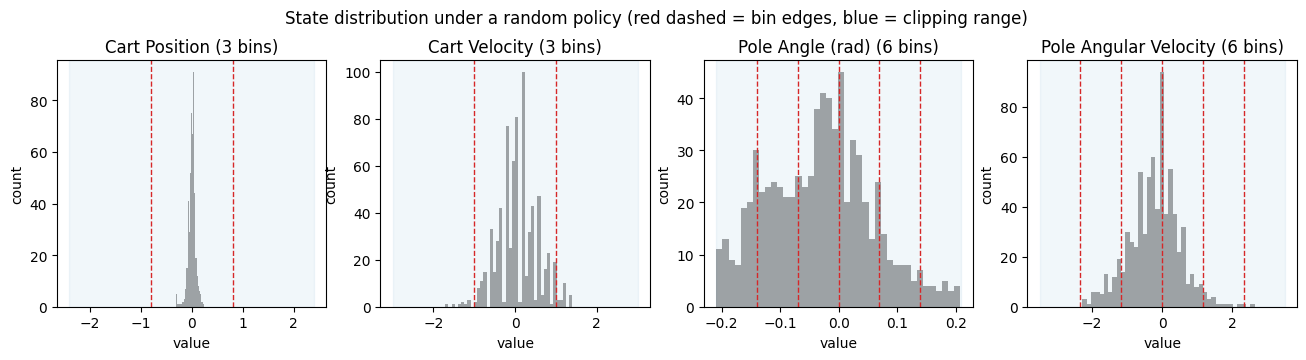

In [47]:
# [제공] 무작위 정책에서 관측되는 상태 분포와 기본 구간 경계 시각화
# 주의: 학습된 정책은 무작위 정책과 다른 상태 분포를 방문합니다. 구간 설계를 고민할 때 참고만 하세요.
env = gym.make(ENV_ID)
env.action_space.seed(0)
samples = []
for ep in range(30):
    obs, _ = env.reset(seed=ep)
    done = False
    while not done:
        samples.append(obs)
        obs, _, terminated, truncated, _ = env.step(env.action_space.sample())
        done = terminated or truncated
env.close()
samples = np.array(samples)

names = ["Cart Position", "Cart Velocity", "Pole Angle (rad)", "Pole Angular Velocity"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for i, ax in enumerate(axes):
    ax.hist(samples[:, i], bins=40, color="tab:gray", alpha=0.7)
    for e in bins_list[i]:
        ax.axvline(e, color="tab:red", ls="--", lw=1)
    lo, hi = STATE_BOUNDS[i]
    ax.axvspan(lo, hi, color="tab:blue", alpha=0.06)
    ax.set_title(f"{names[i]} ({DEFAULT_BINS[i]} bins)")
    ax.set_xlabel("value"); ax.set_ylabel("count")
fig.suptitle("State distribution under a random policy (red dashed = bin edges, blue = clipping range)", y=1.04)
save_fig(fig, "fig_1_1_state_hist")
plt.show()

### ✍️ 확인 문제 1.1
1. 연속형 상태를 이산화해야 하는 이유는 무엇인가?
2. 이산화 구간을 지나치게 **적게** 설정하면 어떤 문제가 발생하는가?
3. 구간을 지나치게 **많이** 설정하면 어떤 문제가 발생하는가?

> ✍️ **답변 1:** Q-table은 상태마다 칸을 하나씩 부터 Q값을 저장하는데 연속형 상태는 값이 무한해서 칸을 만들수 없기 때문이다.
>
> ✍️ **답변 2:** 서로 다른 상황이 같은 칸에 들어가서 구분할 수 없게 된다.
>
> ✍️ **답변 3:** Q-table이 빠르게 커져서 칸을 방문하지 못하게 된다.그렇게 되면 학습이 느려질 수 있다.

## 문제 1.2 Tabular Q-learning 구현 — TODO 3 ~ 7
Q-learning은 다음 TD(Temporal Difference) 업데이트로 Q-table을 갱신합니다.

$$
Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]
$$

| 기호 | 의미 |
|---|---|
| $s, a$ | 현재 (이산화된) 상태와 선택한 행동 |
| $r$ | 행동 후 환경이 준 보상 (CartPole은 매 스텝 +1, **임의로 변경하지 않음**) |
| $s'$ | 다음 (이산화된) 상태 |
| $\alpha$ | 학습률 (`Q_ALPHA`) — 새 정보를 얼마나 반영할지 |
| $\gamma$ | 할인율 (`GAMMA`) — 미래 보상의 현재 가치 |
| $r + \gamma \max_{a'} Q(s',a')$ | **TD target** — 한 스텝 뒤의 추정치로 만든 목표값 (bootstrap) |
| $\delta = \text{TD target} - Q(s,a)$ | **TD error** — 학습 중 기록하는 오차 |

### ⚠️ `terminated`와 `truncated`의 구분
| 상황 | 의미 | TD target |
|---|---|---|
| `terminated = True` (막대가 쓰러짐 / 카트 이탈) | MDP의 **실제 종료 상태**. 이후 받을 보상이 없음 | $r$ (**bootstrap 제거**) |
| `truncated = True` (500 스텝 시간 제한) | 환경 밖의 **인위적 중단**. 상태 $s'$ 자체에는 미래 가치가 있음 | $r + \gamma \max_{a'} Q(s',a')$ (**bootstrap 유지**) |
| 둘 중 하나라도 True | 에피소드가 끝났으므로 | 업데이트 후 `env.reset()` |

> 시간 제한을 실제 종료처럼 처리하면, 500 스텝을 버틴 "가장 좋은" 상태에서 미래 가치가 0이라고 잘못 학습하게 됩니다.

### ε-greedy와 ε 감소 스케줄
확률 ε으로 무작위 행동(탐험), 확률 1-ε으로 현재 Q값이 가장 큰 행동(활용)을 선택합니다. ε은 학습 초반 `EPS_START`에서 전체 스텝의 `EPS_DECAY_FRACTION` 지점까지 `EPS_END`로 **선형 감소**합니다. 이 스케줄은 DQN에서도 그대로 사용해 두 알고리즘의 탐험 조건을 맞춥니다.

In [48]:
def create_q_table(n_bins_per_dim, n_actions):
    # TODO 3: Q-table을 초기화하세요.
    #
    # 이 함수의 목적:
    # - 모든 (이산 상태, 행동) 쌍의 Q값을 저장할 배열 생성
    # - shape = (구간수_0, 구간수_1, 구간수_2, 구간수_3, n_actions)
    # - 초기값은 0으로 둡니다. (CartPole 보상은 양수이므로 0 초기화는 "비관적" 초기화에 가깝습니다)
    #
    # 입력: n_bins_per_dim (예: (3, 3, 6, 6)), n_actions (int)
    # 반환: np.ndarray (dtype float64)
    return np.zeros(tuple(n_bins_per_dim)+ (n_actions,), dtype=np.float64)


def epsilon_greedy(q_values, epsilon, rng):
    # TODO 4: ε-greedy 정책을 구현하세요. (문제 1.3의 DQN에서도 이 함수를 재사용합니다)
    #
    # 이 함수의 목적:
    # - 탐험(Exploration)과 활용(Exploitation)의 균형 조절
    # - 확률 epsilon으로 무작위 행동 선택
    # - 그렇지 않으면 현재 Q값이 가장 높은 행동 선택
    #   (Q값이 같은 행동이 여러 개면 그중 무작위로 선택 — 0으로 초기화된 Q-table에서 한쪽 행동만 고르는 편향 방지)
    #
    # 입력: q_values (shape (n_actions,) np.ndarray), epsilon (float, 0~1),
    #       rng (np.random.Generator — rng.random(), rng.integers(n), rng.choice(arr) 사용)
    if rng.random()< epsilon: return int(rng.integers(len(q_values)))
    best= np.flatnonzero(q_values == np.max(q_values))
    # 반환: 행동 인덱스 (int)
    return int(rng.choice(best))


def linear_epsilon(step, total_steps, eps_start=EPS_START, eps_end=EPS_END, decay_fraction=EPS_DECAY_FRACTION):
    # TODO 5: ε 감소 스케줄을 구현하세요.
    #
    # 이 함수의 목적:
    # - step=0일 때 eps_start
    # - step = total_steps * decay_fraction 일 때 eps_end 에 도달하도록 선형 감소
    # - 그 이후에는 eps_end 유지
    #
    # 입력: step (현재까지의 환경 스텝 수, int), total_steps (전체 예산, int)
    # 반환: 현재 epsilon (float)
    decay_steps= max(total_steps* decay_fraction, 1e-8)
    progress= min(step/ decay_steps, 1)
    return float(eps_start + progress* (eps_end- eps_start))


def q_learning_update(q_table, s, a, r, s_next, terminated, alpha, gamma):
    # TODO 6: Q-learning TD 업데이트를 구현하세요.
    #
    # 이 함수의 목적:
    # 1) TD target 계산
    #    - terminated=True(실제 종료)이면 target = r            ← bootstrap 제거
    #    - 그 외(진행 중이거나 truncated)이면 target = r + gamma * max_a' Q(s_next, a')
    # 2) TD error 계산: td_error = target - Q(s, a)
    # 3) Q(s, a) ← Q(s, a) + alpha * td_error   (q_table을 제자리(in-place)에서 수정)
    #
    # 입력: q_table (np.ndarray), s / s_next (상태 튜플), a (int), r (float),
    #       terminated (bool — truncated는 넘기지 않습니다!), alpha, gamma (float)
    # 반환: td_error (float) — 학습 중 TD error 통계를 기록하는 데 사용
    # 힌트: q_table[s] 는 상태 s의 Q값 벡터, q_table[s + (a,)] 는 Q(s, a) 스칼라입니다.
    if terminated: target= r
    else:
      target= r+gamma*np.max(q_table[s_next])
    td_error = target- q_table[s + (a,)]
    q_table[s + (a,)] += alpha* td_error
    return td_error

In [49]:
# [제공] 문제 1.2 테스트 (TODO 3 ~ 6)
rng = np.random.default_rng(0)

# [TODO 3 확인] Q-table shape
q = create_q_table(DEFAULT_BINS, 2)
assert q.shape == tuple(DEFAULT_BINS) + (2,), f"Q-table shape이 잘못되었습니다: {q.shape}"
assert np.all(q == 0)
print("Q-table shape:", q.shape, "| 원소 수:", q.size)

# [TODO 4 확인] epsilon-greedy — 행동 인덱스 범위와 동작
acts = [epsilon_greedy(np.array([0.0, 1.0]), 0.0, rng) for _ in range(200)]
assert all(a == 1 for a in acts), "epsilon=0이면 항상 Q값이 가장 큰 행동을 골라야 합니다."
acts = [epsilon_greedy(np.array([0.0, 1.0]), 1.0, rng) for _ in range(4000)]
assert set(acts) <= {0, 1} and abs(np.mean(acts) - 0.5) < 0.05, "epsilon=1이면 균등 무작위여야 합니다."
acts = [epsilon_greedy(np.array([0.0, 0.0]), 0.0, rng) for _ in range(4000)]
assert abs(np.mean(acts) - 0.5) < 0.05, "Q값이 동점이면 무작위로 골라야 합니다."
assert all(isinstance(a, int) for a in acts[:10])

# [TODO 5 확인] epsilon 스케줄
assert np.isclose(linear_epsilon(0, 1000, 1.0, 0.05, 0.5), 1.0)
assert np.isclose(linear_epsilon(250, 1000, 1.0, 0.05, 0.5), 0.525)
assert np.isclose(linear_epsilon(500, 1000, 1.0, 0.05, 0.5), 0.05)
assert np.isclose(linear_epsilon(900, 1000, 1.0, 0.05, 0.5), 0.05)

# [TODO 6 확인] 손으로 계산한 값과 비교
q = create_q_table((2, 2, 2, 2), 2)
s, s_next = (0, 0, 0, 0), (1, 1, 1, 1)
q[s_next] = [1.0, 3.0]
td = q_learning_update(q, s, 1, 1.0, s_next, terminated=False, alpha=0.5, gamma=0.9)
# target = 1 + 0.9 * max(1, 3) = 3.7 → td = 3.7 - 0 = 3.7 → Q = 0 + 0.5 * 3.7 = 1.85
assert np.isclose(td, 3.7) and np.isclose(q[s + (1,)], 1.85), f"진행 중 전이 업데이트 오류: td={td}, Q={q[s + (1,)]}"
td = q_learning_update(q, s, 1, 1.0, s_next, terminated=True, alpha=0.5, gamma=0.9)
# target = 1 (bootstrap 제거) → td = 1 - 1.85 = -0.85 → Q = 1.85 + 0.5 * (-0.85) = 1.425
assert np.isclose(td, -0.85) and np.isclose(q[s + (1,)], 1.425), "terminated=True일 때 bootstrap을 제거해야 합니다."
assert q[s + (0,)] == 0.0, "선택하지 않은 행동의 Q값은 바뀌면 안 됩니다."
print("✅ 문제 1.2 테스트 통과 (TODO 3 ~ 6)")

Q-table shape: (3, 3, 6, 6, 2) | 원소 수: 648
✅ 문제 1.2 테스트 통과 (TODO 3 ~ 6)


### 평가 함수 — TODO 7
학습 중의 에피소드 리턴은 **ε-탐험이 섞인 행동**으로 얻은 값이므로 정책의 실제 성능을 과소평가할 수 있습니다. 그래서 학습과 **분리된 평가 환경**에서 **탐험을 제외한(greedy) 정책**을 따로 평가합니다.

- 평가 에피소드 $i$는 항상 `seed = EVAL_SEED_BASE + i`로 reset → 모든 알고리즘 · 모든 평가 시점이 **같은 초기 상태 집합**으로 평가됩니다.
- 반환하는 `std`는 "같은 정책을 여러 초기 상태에서 돌렸을 때의 리턴 표준편차"입니다. 1.4에서 계산할 **시드 간 표준편차**와는 다른 개념이니 구분하세요.

이 함수는 Q-learning(1.2)과 DQN(1.3)에서 **똑같이** 사용합니다. 정책은 `policy_fn(obs) -> action` 형태의 함수로 전달됩니다.

In [50]:
def evaluate_policy(policy_fn, n_episodes=EVAL_EPISODES, seed_base=EVAL_SEED_BASE, env_id=ENV_ID):
    # TODO 7: 탐험을 제외한 정책을 별도 평가 환경에서 평가하세요.
    #
    # 이 함수의 목적:
    # - 학습 환경과 분리된 평가 환경을 새로 생성: eval_env = gym.make(env_id)
    # - n_episodes개의 에피소드를 실행. 에피소드 i는 eval_env.reset(seed=seed_base + i)로 시작
    # - 매 스텝 action = policy_fn(obs) 로 행동 선택 (policy_fn 안에는 탐험이 없습니다)
    # - terminated 또는 truncated가 True가 될 때까지 진행하며 보상을 합산
    # - 평가가 끝나면 eval_env.close()
    #
    # 입력: policy_fn (obs → int 행동), n_episodes (int), seed_base (int), env_id (str)
    # 반환: dict {
    #   "mean":    리턴 평균 (float),
    #   "std":     리턴 표준편차 (float, np.std 사용),
    #   "returns": 에피소드별 리턴 리스트,
    #   "lengths": 에피소드별 길이 리스트,
    # }
    eval_env = gym.make(env_id)
    returns, lengths = [], []
    for i in range(n_episodes):
        obs, _ = eval_env.reset(seed=seed_base + i)
        ep_ret, ep_len, done = 0.0, 0, False
        while not done:
            action = policy_fn(obs)
            obs, reward, terminated, truncated, _ = eval_env.step(action)
            ep_ret += reward
            ep_len += 1
            done = terminated or truncated
        returns.append(ep_ret)
        lengths.append(ep_len)
    eval_env.close()
    return {"mean": float(np.mean(returns)), "std": float(np.std(returns)),
            "returns": returns, "lengths": lengths}

In [51]:
# [제공] TODO 7 테스트
always_left = lambda obs: 0
res1 = evaluate_policy(always_left, n_episodes=5)
res2 = evaluate_policy(always_left, n_episodes=5)
assert set(res1) >= {"mean", "std", "returns", "lengths"}
assert len(res1["returns"]) == 5
assert res1["returns"] == res2["returns"], "같은 결정적 정책은 같은 평가 시드에서 같은 결과를 내야 합니다."
assert np.isclose(res1["mean"], np.mean(res1["returns"]))
# 막대 각도 기반 휴리스틱: 기울어진 쪽으로 카트를 민다 — 항상 왼쪽보다 훨씬 오래 버텨야 합니다.
heuristic = lambda obs: int(obs[2] + 0.5 * obs[3] > 0)
res_h = evaluate_policy(heuristic, n_episodes=5)
print(f"항상 왼쪽 정책: {res1['mean']:.1f} ± {res1['std']:.1f} | 각도 휴리스틱: {res_h['mean']:.1f} ± {res_h['std']:.1f}")
assert res_h["mean"] > res1["mean"]
print("✅ TODO 7 테스트 통과")

항상 왼쪽 정책: 9.2 ± 0.7 | 각도 휴리스틱: 500.0 ± 0.0
✅ TODO 7 테스트 통과


### [제공] Tabular Q-learning 학습 루프
아래 함수는 TODO 2 ~ 7을 조합해 **환경 상호작용 스텝 수 기준**으로 학습합니다. 직접 작성할 부분은 없지만 다음을 꼭 읽고 이해하세요.
- `q_learning_update`에는 `terminated`만 전달하고, 에피소드 리셋은 `terminated or truncated`일 때 합니다.
- 학습 예산이 끝나는 순간 진행 중이던 에피소드는 완료되지 않았으므로 학습 리턴 기록에서 제외됩니다.
- 기록 항목: 에피소드별 리턴과 종료 시점의 스텝 수, 주기적 평가 평균 · 표준편차, `LOG_INTERVAL`마다의 |TD error| 평균 · 표준편차, ε, 방문한 상태 비율

In [52]:
def make_q_policy(q_table, bins_list):
    """[제공] Q-table로부터 탐험 없는 greedy 정책 함수를 만듭니다."""
    def policy(obs):
        return int(np.argmax(q_table[discretize_state(obs, bins_list)]))
    return policy


def train_q_learning(seed, total_steps=TOTAL_STEPS, n_bins=DEFAULT_BINS, alpha=Q_ALPHA, gamma=GAMMA,
                     eval_interval=EVAL_INTERVAL, eval_episodes=EVAL_EPISODES, verbose=True):
    """[제공] 환경 상호작용 스텝 예산(total_steps) 기준 Tabular Q-learning 학습."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    bins_list = build_bins_list(n_bins)
    q_table = create_q_table(n_bins, env.action_space.n)
    policy = make_q_policy(q_table, bins_list)   # q_table을 참조하므로 학습이 진행되면 정책도 바뀝니다.

    log = {"algo": "Q-learning", "seed": seed, "n_bins": tuple(n_bins), "total_steps": total_steps,
           "episode_returns": [], "episode_end_steps": [], "episode_lengths": [],
           "eval_steps": [], "eval_mean": [], "eval_std": [], "visited_ratio": [],
           "stat_steps": [], "td_abs_mean": [], "td_abs_std": [], "epsilon": []}
    t0 = time.time()

    def run_eval(step):
        res = evaluate_policy(policy, n_episodes=eval_episodes)
        log["eval_steps"].append(step)
        log["eval_mean"].append(res["mean"])
        log["eval_std"].append(res["std"])
        # 한 번이라도 업데이트된(0이 아닌 Q값을 가진) 상태의 비율 — 방문한 상태 비율의 근사치
        log["visited_ratio"].append(float(np.mean(np.any(q_table != 0, axis=-1))))
        if verbose:
            print(f"[Q-learning | seed {seed}] step {step:>6}/{total_steps} | eval {res['mean']:6.1f} ± {res['std']:5.1f}"
                  f" | eps {linear_epsilon(step, total_steps):.3f} | {time.time() - t0:5.1f}s")

    run_eval(0)
    obs, _ = env.reset(seed=seed)
    s = discretize_state(obs, bins_list)
    ep_ret, ep_len, td_window = 0.0, 0, []

    for step in range(1, total_steps + 1):
        epsilon = linear_epsilon(step - 1, total_steps)
        a = epsilon_greedy(q_table[s], epsilon, rng)
        obs_next, reward, terminated, truncated, _ = env.step(a)
        s_next = discretize_state(obs_next, bins_list)

        # 실제 종료(terminated)만 bootstrap 제거 조건으로 전달합니다. truncated는 전달하지 않습니다.
        td_error = q_learning_update(q_table, s, a, reward, s_next, terminated, alpha, gamma)
        td_window.append(abs(td_error))
        ep_ret += reward
        ep_len += 1
        s = s_next

        if terminated or truncated:          # 실제 종료 또는 시간 제한 → 에피소드 리셋
            log["episode_returns"].append(ep_ret)
            log["episode_end_steps"].append(step)
            log["episode_lengths"].append(ep_len)
            obs, _ = env.reset()
            s = discretize_state(obs, bins_list)
            ep_ret, ep_len = 0.0, 0

        if step % LOG_INTERVAL == 0:
            log["stat_steps"].append(step)
            log["td_abs_mean"].append(float(np.mean(td_window)))
            log["td_abs_std"].append(float(np.std(td_window)))
            log["epsilon"].append(epsilon)
            td_window = []

        if step % eval_interval == 0:
            run_eval(step)

    if total_steps % eval_interval != 0:
        run_eval(total_steps)
    env.close()
    log["final_q_table"] = q_table
    log["wall_time_sec"] = time.time() - t0
    return log


# 빠른 동작 확인 (짧은 예산)
_smoke = train_q_learning(seed=0, total_steps=2_000, eval_interval=1_000, eval_episodes=2, verbose=False)
print(f"동작 확인: 완료 에피소드 {len(_smoke['episode_returns'])}개, 평가 시점 {_smoke['eval_steps']}, "
      f"TD 통계 기록 {len(_smoke['td_abs_mean'])}회, 소요 {_smoke['wall_time_sec']:.1f}s")

동작 확인: 완료 에피소드 48개, 평가 시점 [0, 1000, 2000], TD 통계 기록 4회, 소요 1.0s


### ✍️ 확인 문제 1.2
1. 위 학습 루프에서 `q_learning_update`에 `terminated or truncated`가 아니라 `terminated`만 전달하는 이유를 CartPole의 500 스텝 시간 제한과 연결해 설명하시오.
2. 학습 중 TD error의 크기가 줄어드는 것은 "정책이 좋아졌다"는 뜻인가? 그렇지 않을 수 있는 경우를 하나 제시하시오. (1.4의 그래프 D를 본 뒤 다시 돌아와 답을 보완해도 좋습니다.)

> ✍️ **답변 1:** truncated는 500 스텝 시간 제한으로 끊긴 것일 뿐 막대는 아직 서 있어서 미래 보상이 남아 있다. 이걸 종료로 처리하면 가장 좋은 상태의 가치를 0으로 잘못 배우므로, 실제 종료인 terminated만 전달한다.
>
> ✍️ **답변 2:** 아니다. 나쁜 정책이 몇 개 상태만 반복 방문해도 TD error는 작아진다. 실제로 |TD error|는 내내 약 2로 평평했는데 평가 리턴은 42.5~173.1 사이를 오르내렸다.

## 문제 1.3 DQN 구현 — TODO 8 ~ 12
DQN은 Q-table 대신 **신경망** $Q_\theta(s, a)$로 Q함수를 근사합니다. Atari DQN은 이미지 입력이라 CNN을 사용하지만, **CartPole의 관측값은 4차원 벡터**이므로 **MLP(다층 퍼셉트론)**면 충분합니다. 이산화가 필요 없고, 비슷한 상태 사이에서 신경망이 자연스럽게 일반화합니다.

**구성 요소**
| # | 구성 | 역할 | TODO |
|---|---|---|---|
| 1 | Q-Network (MLP) | 상태 → 행동별 Q값 | **8** (forward) |
| 2 | Replay Buffer | 경험 저장, **무작위 미니배치 샘플링**으로 연속된 경험 간 상관관계 완화 · 데이터 재사용 | **9** (sample) |
| 3 | ε-greedy | 탐험 (1.2의 `epsilon_greedy` 재사용) | – |
| 4 | Target Network | 느리게 갱신되는 복사본으로 **target을 고정** → 움직이는 목표 문제 완화 | **12** |
| 5 | TD target | Bellman target 계산 | **10** |
| 6 | Loss 계산 | $Q_\theta(s,a)$와 target의 차이 (Huber loss) | **11** |
| 7 | Optimizer 업데이트 | 역전파 · gradient clipping · Adam step | **11** |

**DQN target**

$$
y = r + \gamma (1 - d) \max_{a'} Q_{\text{target}}(s', a'), \qquad \mathcal{L}(\theta) = \text{Huber}\big(Q_\theta(s,a) - y\big)
$$

- $d$는 **실제 MDP 종료 여부(`terminated`)**입니다. 시간 제한에 의한 `truncated`는 $d = 0$으로 두어 bootstrap을 유지합니다. 그래서 Replay Buffer에는 `terminated`만 저장합니다.
- $y$는 **상수(목표값)**로 취급해야 합니다. $y$를 계산하는 경로로 gradient가 흐르면 목표값까지 함께 움직여 학습이 불안정해집니다 → `torch.no_grad()` 사용.

> ⚠️ **DQN의 loss는 지도학습의 loss와 다릅니다.** target $y$ 자체가 학습 중인 네트워크로 만들어지고, 정책이 바뀌면 버퍼의 데이터 분포도 바뀝니다. 따라서 **loss가 감소한다고 에피소드 보상이 증가한다는 보장은 없으며**, 반대로 성능이 좋아지는 중에 loss가 커질 수도 있습니다(에피소드가 길어지면 Q값의 크기 자체가 커지기 때문). 성능은 반드시 평가 리턴으로 판단하세요.

In [53]:
class QNetwork(nn.Module):
    """[제공: 레이어 정의 / TODO 8: forward] CartPole용 2층 MLP Q-Network."""

    def __init__(self, obs_dim, n_actions, hidden_dim=128):
        super().__init__()
        self.fc1 = nn.Linear(obs_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, n_actions)

    def forward(self, x):
        # TODO 8: Q-Network의 forward 연산을 구현하세요.
        #
        # 이 함수의 목적:
        # - 상태 배치 x를 받아 각 행동의 Q값을 출력
        # - 구조: fc1 → ReLU → fc2 → ReLU → out   (출력층에는 활성화 함수를 쓰지 않습니다.
        #   Q값은 음수/양수 모두 가능한 실수이기 때문입니다.)
        #
        # 입력: x — torch.FloatTensor, shape (batch_size, obs_dim)
        # 반환: torch.FloatTensor, shape (batch_size, n_actions)
        x= F.relu(self.fc1(x))
        x= F.relu(self.fc2(x))
        return self.out(x)


class ReplayBuffer:
    """[제공: 저장 / TODO 9: 샘플링] 고정 용량의 원형(circular) Experience Replay 버퍼."""

    def __init__(self, capacity, obs_dim, seed=0):
        self.capacity = capacity
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.terminated = np.zeros(capacity, dtype=np.float32)   # truncated는 저장하지 않습니다.
        self.ptr, self.size = 0, 0
        self.rng = np.random.default_rng(seed)

    def add(self, obs, action, reward, next_obs, terminated):
        self.obs[self.ptr] = obs
        self.actions[self.ptr] = action
        self.rewards[self.ptr] = reward
        self.next_obs[self.ptr] = next_obs
        self.terminated[self.ptr] = float(terminated)
        self.ptr = (self.ptr + 1) % self.capacity      # 가득 차면 가장 오래된 경험부터 덮어씀
        self.size = min(self.size + 1, self.capacity)

    def __len__(self):
        return self.size

    def sample(self, batch_size):
        # TODO 9: Replay Buffer에서 무작위 미니배치를 추출하세요.
        #
        # 이 함수의 목적:
        # - 연속된 경험 간 상관관계를 완화하기 위한 단계입니다.
        # - 현재 저장된 경험(0 ~ self.size-1) 중에서 batch_size개의 인덱스를 무작위로 고르고
        #   (self.rng.integers 사용, 중복 허용)
        # - 같은 인덱스로 obs, actions, rewards, next_obs, terminated를 함께 꺼내야
        #   (s, a, r, s', d) 전이의 짝이 유지됩니다.
        #
        # 반환: dict — 모든 값은 DEVICE 위의 torch.Tensor
        #   "obs":        float32, shape (B, obs_dim)
        #   "actions":    int64,   shape (B,)
        #   "rewards":    float32, shape (B,)
        #   "next_obs":   float32, shape (B, obs_dim)
        #   "terminated": float32, shape (B,)   (1.0 = 실제 종료)
        # 힌트: torch.as_tensor(numpy_array, device=DEVICE)
      idx= self.rng.integers(0, self.size, size=batch_size)
      return{
            "obs":torch.as_tensor(self.obs[idx], device=DEVICE),
            "actions":torch.as_tensor(self.actions[idx], device=DEVICE),
            "rewards":torch.as_tensor(self.rewards[idx], device=DEVICE),
            "next_obs":torch.as_tensor(self.next_obs[idx], device=DEVICE),
            "terminated":torch.as_tensor(self.terminated[idx], device=DEVICE),
        }

In [54]:
def compute_td_target(target_net, rewards, next_obs, terminated, gamma):
    # TODO 10: Target Network를 사용하여 Bellman target을 계산하세요.
    #
    # 이 함수의 목적:
    # - y = r + gamma * (1 - d) * max_a' Q_target(s', a')
    # - 다음 상태에서 최대 Q값을 추정하되,
    #   이 계산의 목표값 경로로 gradient가 전파되지 않아야 합니다.  → torch.no_grad()
    # - d = terminated (실제 종료일 때만 1). truncated 전이는 d = 0으로 버퍼에 저장되어 있습니다.
    #
    # 입력: target_net (QNetwork 또는 obs → Q값을 반환하는 함수),
    #       rewards (B,), next_obs (B, obs_dim), terminated (B,) — torch.Tensor, gamma (float)
    # 반환: y — torch.Tensor, shape (B,), requires_grad == False
    # 힌트: tensor.max(dim=1).values
    with torch.no_grad():
        next_q = target_net(next_obs).max(dim=1).values
        y = rewards + gamma * (1.0 - terminated) * next_q
    return y


def dqn_update(q_net, target_net, optimizer, batch, gamma, grad_clip=DQN_CONFIG["grad_clip"]):
    # TODO 11: DQN 손실을 계산하고 Optimizer로 파라미터를 업데이트하세요.
    #
    # 이 함수의 목적 (미니배치 1개에 대한 gradient step 1회):
    # 1) 현재 Q값: q_net(batch["obs"])에서 실제로 선택했던 행동의 Q값만 골라냄
    #    → Q(s, a), shape (B,)    힌트: .gather(1, actions.unsqueeze(1)).squeeze(1)
    # 2) 목표값: compute_td_target(target_net, ...)  (TODO 10)
    # 3) 손실: F.smooth_l1_loss(Q(s, a), y)   (Huber loss — 큰 TD error에 덜 민감)
    # 4) optimizer.zero_grad() → loss.backward()
    #    → nn.utils.clip_grad_norm_(q_net.parameters(), grad_clip) → optimizer.step()
    #
    # 반환: (loss 값 float, Q(s, a)의 배치 평균 float)  — 학습 곡선 기록용 (.item() 사용)
    q_sa = q_net(batch["obs"]).gather(1, batch["actions"].unsqueeze(1)).squeeze(1)
    y = compute_td_target(target_net, batch["rewards"], batch["next_obs"], batch["terminated"], gamma)  # 2) 목표값
    loss = F.smooth_l1_loss(q_sa, y)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(q_net.parameters(), grad_clip)
    optimizer.step()
    return loss.item(), q_sa.mean().item()


def update_target_network(q_net, target_net, tau=1.0):
    # TODO 12: Target Network를 업데이트하세요.
    #
    # 이 함수의 목적:
    # - tau >= 1.0 : 하드 업데이트 — q_net의 파라미터를 target_net에 그대로 복사
    #                (힌트: nn.Module의 state_dict() / load_state_dict() 메서드)
    # - 0 < tau < 1: 소프트 업데이트 — θ_target ← τ·θ + (1-τ)·θ_target  (torch.no_grad() 안에서)
    # - 이 과제의 학습 루프는 target_update_interval 스텝마다 tau=1.0으로 호출합니다.
    #
    # 입력: q_net, target_net (QNetwork), tau (float)
    # 반환: 없음 (target_net을 제자리에서 수정)
    if tau >= 1.0: target_net.load_state_dict(q_net.state_dict())
    else:
        with torch.no_grad():
            for p, tp in zip(q_net.parameters(), target_net.parameters()):
                tp.mul_(1.0 - tau).add_(tau * p)

In [55]:
# [제공] 문제 1.3 테스트 (TODO 8 ~ 12)
torch.manual_seed(0)

# [TODO 8 확인] forward shape
net = QNetwork(4, 2).to(DEVICE)
out = net(torch.zeros(5, 4, device=DEVICE))
assert out.shape == (5, 2), f"출력 shape은 (5, 2)여야 합니다: {tuple(out.shape)}"

# [TODO 9 확인] Replay Buffer 샘플링 — shape, dtype, 전이의 짝 유지
buf = ReplayBuffer(100, 4, seed=0)
for i in range(10):
    buf.add(np.full(4, i, dtype=np.float32), i % 2, 1.0, np.full(4, i + 1, dtype=np.float32), terminated=(i == 9))
batch = buf.sample(32)
assert batch["obs"].shape == (32, 4) and batch["next_obs"].shape == (32, 4)
assert batch["actions"].shape == (32,) and batch["actions"].dtype == torch.int64
assert batch["rewards"].dtype == torch.float32 and batch["terminated"].dtype == torch.float32
assert torch.all(batch["next_obs"][:, 0] == batch["obs"][:, 0] + 1), "(s, s') 짝이 깨졌습니다. 같은 인덱스로 꺼내야 합니다."
assert torch.all(batch["actions"] == (batch["obs"][:, 0].long() % 2)), "(s, a) 짝이 깨졌습니다."
assert torch.all(batch["terminated"] == (batch["obs"][:, 0] == 9).float())
assert batch["obs"][:, 0].max() <= 9, "아직 저장되지 않은 칸(size 이상)을 샘플링하면 안 됩니다."

# [TODO 10 확인] 손으로 계산한 target과 비교
fixed_target = lambda x: torch.tensor([[1.0, 3.0], [2.0, 0.5]], device=DEVICE)
y = compute_td_target(fixed_target, torch.tensor([1.0, 1.0], device=DEVICE), torch.zeros(2, 4, device=DEVICE),
                      torch.tensor([0.0, 1.0], device=DEVICE), gamma=0.9)
assert torch.allclose(y, torch.tensor([3.7, 1.0], device=DEVICE)), f"target 오류: {y} (기대값 [3.7, 1.0])"
y_net = compute_td_target(net, batch["rewards"], batch["next_obs"], batch["terminated"], 0.99)
assert y_net.shape == (32,) and not y_net.requires_grad, "target 경로로 gradient가 흐르면 안 됩니다 (torch.no_grad)."

# [TODO 11 확인] loss가 유한한 float이고, q_net 파라미터만 바뀌고 target_net은 그대로인지
q_net, target_net = QNetwork(4, 2).to(DEVICE), QNetwork(4, 2).to(DEVICE)
target_before = [p.clone() for p in target_net.parameters()]
q_before = [p.clone() for p in q_net.parameters()]
opt = torch.optim.Adam(q_net.parameters(), lr=1e-3)
loss, q_mean = dqn_update(q_net, target_net, opt, batch, 0.99)
assert isinstance(loss, float) and np.isfinite(loss) and isinstance(q_mean, float)
assert any(not torch.equal(a, b) for a, b in zip(q_before, q_net.parameters())), "q_net 파라미터가 업데이트되지 않았습니다."
assert all(torch.equal(a, b) for a, b in zip(target_before, target_net.parameters())), "target_net은 dqn_update에서 바뀌면 안 됩니다."

# [TODO 12 확인] 하드 / 소프트 업데이트
update_target_network(q_net, target_net, tau=1.0)
assert all(torch.equal(a, b) for a, b in zip(q_net.parameters(), target_net.parameters()))
t2 = QNetwork(4, 2).to(DEVICE)
t2_before = [p.clone() for p in t2.parameters()]
update_target_network(q_net, t2, tau=0.1)
for p, tp, tb in zip(q_net.parameters(), t2.parameters(), t2_before):
    assert torch.allclose(tp, 0.1 * p + 0.9 * tb, atol=1e-6), "소프트 업데이트 식을 확인하세요."
print(f"✅ 문제 1.3 테스트 통과 (TODO 8 ~ 12) | 예시 loss={loss:.4f}, mean Q(s,a)={q_mean:.4f}")

✅ 문제 1.3 테스트 통과 (TODO 8 ~ 12) | 예시 loss=1.1687, mean Q(s,a)=-0.2847


### [제공] DQN 학습 루프
TODO 4, 5, 7 ~ 12를 조합합니다. Q-learning 학습 루프와 **같은 예산 · 같은 ε 스케줄 · 같은 평가 함수 · 같은 평가 시점**을 사용합니다.
- 버퍼에는 `terminated`만 저장합니다 (`truncated` 전이는 bootstrap 유지).
- `learning_starts` 스텝까지는 경험만 모으고, 이후 `train_freq` 스텝마다 미니배치 1개로 업데이트합니다.
- `target_update_interval` 스텝마다 Target Network를 하드 업데이트합니다.
- 기록 항목: 에피소드 리턴, 주기적 평가 평균 · 표준편차, `LOG_INTERVAL`마다의 평균 loss와 평균 Q(s,a), ε

In [56]:
def train_dqn(seed, total_steps=TOTAL_STEPS, config=DQN_CONFIG, gamma=GAMMA,
              eval_interval=EVAL_INTERVAL, eval_episodes=EVAL_EPISODES, verbose=True):
    """[제공] 환경 상호작용 스텝 예산(total_steps) 기준 DQN 학습."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    obs_dim, n_actions = env.observation_space.shape[0], env.action_space.n

    q_net = QNetwork(obs_dim, n_actions, config["hidden_dim"]).to(DEVICE)
    target_net = QNetwork(obs_dim, n_actions, config["hidden_dim"]).to(DEVICE)
    update_target_network(q_net, target_net, tau=1.0)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=config["lr"])
    buffer = ReplayBuffer(config["buffer_size"], obs_dim, seed=seed)

    def q_values_of(o):
        with torch.no_grad():
            return q_net(torch.as_tensor(o, dtype=torch.float32, device=DEVICE).unsqueeze(0))[0].cpu().numpy()

    def greedy_policy(o):              # 평가용: 탐험 없음
        return int(np.argmax(q_values_of(o)))

    log = {"algo": "DQN", "seed": seed, "total_steps": total_steps, "config": dict(config),
           "episode_returns": [], "episode_end_steps": [], "episode_lengths": [],
           "eval_steps": [], "eval_mean": [], "eval_std": [],
           "stat_steps": [], "loss_mean": [], "q_mean": [], "epsilon": [], "n_updates": 0}
    t0 = time.time()

    def run_eval(step):
        res = evaluate_policy(greedy_policy, n_episodes=eval_episodes)
        log["eval_steps"].append(step)
        log["eval_mean"].append(res["mean"])
        log["eval_std"].append(res["std"])
        if verbose:
            print(f"[DQN        | seed {seed}] step {step:>6}/{total_steps} | eval {res['mean']:6.1f} ± {res['std']:5.1f}"
                  f" | eps {linear_epsilon(step, total_steps):.3f} | {time.time() - t0:5.1f}s")

    run_eval(0)
    obs, _ = env.reset(seed=seed)
    ep_ret, ep_len = 0.0, 0
    loss_window, q_window = [], []

    for step in range(1, total_steps + 1):
        epsilon = linear_epsilon(step - 1, total_steps)
        action = epsilon_greedy(q_values_of(obs), epsilon, rng)       # 1.2의 ε-greedy 재사용
        next_obs, reward, terminated, truncated, _ = env.step(action)
        buffer.add(obs, action, reward, next_obs, terminated)          # d = terminated (truncated 아님)
        ep_ret += reward
        ep_len += 1
        obs = next_obs

        if step > config["learning_starts"] and step % config["train_freq"] == 0:
            batch = buffer.sample(config["batch_size"])
            loss, q_mean = dqn_update(q_net, target_net, optimizer, batch, gamma, config["grad_clip"])
            loss_window.append(loss)
            q_window.append(q_mean)
            log["n_updates"] += 1

        if step % config["target_update_interval"] == 0:
            update_target_network(q_net, target_net, tau=1.0)

        if terminated or truncated:
            log["episode_returns"].append(ep_ret)
            log["episode_end_steps"].append(step)
            log["episode_lengths"].append(ep_len)
            obs, _ = env.reset()
            ep_ret, ep_len = 0.0, 0

        if step % LOG_INTERVAL == 0:
            log["stat_steps"].append(step)
            log["loss_mean"].append(float(np.mean(loss_window)) if loss_window else np.nan)
            log["q_mean"].append(float(np.mean(q_window)) if q_window else np.nan)
            log["epsilon"].append(epsilon)
            loss_window, q_window = [], []

        if step % eval_interval == 0:
            run_eval(step)

    if total_steps % eval_interval != 0:
        run_eval(total_steps)
    env.close()
    log["final_state_dict"] = {k: v.detach().cpu().clone() for k, v in q_net.state_dict().items()}
    log["obs_dim"], log["n_actions"] = obs_dim, n_actions
    log["wall_time_sec"] = time.time() - t0
    return log


# 빠른 동작 확인 (짧은 예산)
_smoke = train_dqn(seed=0, total_steps=1_500, eval_interval=750, eval_episodes=2, verbose=False)
print(f"동작 확인: 완료 에피소드 {len(_smoke['episode_returns'])}개, gradient update {_smoke['n_updates']}회, "
      f"평가 시점 {_smoke['eval_steps']}, 소요 {_smoke['wall_time_sec']:.1f}s")

동작 확인: 완료 에피소드 20개, gradient update 500회, 평가 시점 [0, 750, 1500], 소요 2.6s


### ✍️ 확인 문제 1.3
1. 이 구현에서 DQN은 환경 1스텝당 gradient update를 몇 번 수행하며, Tabular Q-learning은 1스텝당 Q값 업데이트를 몇 번 수행하는가? **Experience Replay가 데이터 활용 방식에 어떤 차이를 만드는지** 이 관점에서 설명하시오.
2. `compute_td_target`에서 `torch.no_grad()`를 빼면 어떤 일이 생기는가? Target Network가 별도로 있다는 사실과 연결해 설명하시오.

> ✍️ **답변 1:** DQN은 1스텝당 1번 업데이트하되 버퍼에서 뽑은 경험 64개를 쓰고, Q-learning은 방금 경험 하나로 한 칸만 갱신하고 버린다. Replay 덕분에 과거 경험을 재사용하고 연속된 경험의 상관관계도 줄인다.
>
> ✍️ **답변 2:** 목표값 y 쪽으로도 기울기가 흘러 불필요한 계산이 생긴다. Target Network를 따로 둔 이유가 목표값을 고정하기 위해서이므로 y는 상수로 취급해야 한다.

## 문제 1.4 모델 학습 및 학습 곡선 시각화 — TODO 13
### 비교 조건 (공정한 비교를 위한 통제)
| 조건 | 설정 |
|---|---|
| 환경 버전 | 두 알고리즘 모두 `CartPole-v1` |
| 학습 예산 | **환경 상호작용 스텝 수** `TOTAL_STEPS` (에피소드 수가 아님) |
| 보상 정의 | 환경 기본 보상 그대로 (+1/step) — 보상 shaping 없음 |
| 시드 | 같은 `SEEDS` 목록 |
| 탐험 | 같은 ε 선형 감소 스케줄 |
| 평가 | 같은 평가 시점(`EVAL_INTERVAL`), 같은 평가 에피소드 수, 같은 평가 초기 상태(`EVAL_SEED_BASE`), 탐험 없는 greedy 정책 |
| 통제되지 **않은** 것 | 계산량(DQN은 매 스텝 신경망 업데이트), 모델 용량, 학습률의 의미(α vs Adam lr) → 1.7에서 한계로 논의 |

> FULL_MODE에서는 시드 3개 × 두 알고리즘을 학습합니다. 학습 로그는 `results/logs/cartpole_logs.pkl`에 저장되며, 런타임이 끊긴 경우 아래 셀의 `LOAD_SAVED_LOGS = True`로 다시 학습하지 않고 불러올 수 있습니다.

In [57]:
# 약 8분 소요(로컬 환경별로 상이)
# [제공] 실험 조건 기록 + Q-learning / DQN 학습 실행
setup = pd.DataFrame([
    {"item": "env", "Q-learning": ENV_ID, "DQN": ENV_ID},
    {"item": "env steps per seed", "Q-learning": TOTAL_STEPS, "DQN": TOTAL_STEPS},
    {"item": "seeds", "Q-learning": str(SEEDS), "DQN": str(SEEDS)},
    {"item": "reward", "Q-learning": "env default (+1/step)", "DQN": "env default (+1/step)"},
    {"item": "epsilon schedule", "Q-learning": f"{EPS_START}->{EPS_END} in {EPS_DECAY_FRACTION:.0%}", "DQN": f"{EPS_START}->{EPS_END} in {EPS_DECAY_FRACTION:.0%}"},
    {"item": "eval every / episodes", "Q-learning": f"{EVAL_INTERVAL} / {EVAL_EPISODES}", "DQN": f"{EVAL_INTERVAL} / {EVAL_EPISODES}"},
    {"item": "state input", "Q-learning": f"discretized bins {DEFAULT_BINS}", "DQN": "raw 4-dim vector"},
    {"item": "learning rate", "Q-learning": f"alpha={Q_ALPHA}", "DQN": f"Adam lr={DQN_CONFIG['lr']}"},
    {"item": "updates per env step", "Q-learning": "1 (single transition)", "DQN": f"1 minibatch of {DQN_CONFIG['batch_size']} (after {DQN_CONFIG['learning_starts']} steps)"},
]).set_index("item")
display(setup)
save_table(setup, "experiment_setup")

LOAD_SAVED_LOGS = False
LOG_PATH = os.path.join(LOG_DIR, "cartpole_logs.pkl")

if LOAD_SAVED_LOGS and os.path.exists(LOG_PATH):
    with open(LOG_PATH, "rb") as f:
        saved = pickle.load(f)
    q_logs, dqn_logs = saved["q_logs"], saved["dqn_logs"]
    print(f"📂 저장된 로그를 불러왔습니다: {LOG_PATH}")
else:
    q_logs, dqn_logs = [], []
    for seed in SEEDS:
        q_logs.append(train_q_learning(seed))
        dqn_logs.append(train_dqn(seed))
    with open(LOG_PATH, "wb") as f:
        pickle.dump({"q_logs": q_logs, "dqn_logs": dqn_logs, "fast_mode": FAST_MODE}, f)
    print(f"💾 학습 로그 저장: {LOG_PATH}")

# 예산이 실제로 같았는지 확인
budget = pd.DataFrame([{
    "algo": lg["algo"], "seed": lg["seed"], "env_steps": lg["total_steps"],
    "completed_episodes": len(lg["episode_returns"]), "eval_points": len(lg["eval_steps"]),
    "wall_time_sec": round(lg["wall_time_sec"], 1),
} for lg in q_logs + dqn_logs])
display(budget)
assert budget["env_steps"].nunique() == 1, "두 알고리즘의 환경 스텝 예산이 다릅니다!"

,Q-learning,DQN
item,,
env,CartPole-v1,CartPole-v1
env steps per seed,60000,60000
seeds,"[0, 1, 2]","[0, 1, 2]"
reward,env default (+1/step),env default (+1/step)
epsilon schedule,1.0->0.05 in 30%,1.0->0.05 in 30%
eval every / episodes,5000 / 10,5000 / 10
state input,"discretized bins (3, 3, 6, 6)",raw 4-dim vector
learning rate,alpha=0.1,Adam lr=0.0005
updates per env step,1 (single transition),1 minibatch of 64 (after 1000 steps)


💾 표 저장: results/tables/experiment_setup.csv
[Q-learning | seed 0] step      0/60000 | eval    9.2 ±   0.7 | eps 1.000 |   0.0s
[Q-learning | seed 0] step   5000/60000 | eval  164.4 ±  47.7 | eps 0.736 |   1.6s
[Q-learning | seed 0] step  10000/60000 | eval  171.5 ±  39.9 | eps 0.472 |   2.9s
[Q-learning | seed 0] step  15000/60000 | eval   42.5 ±  33.3 | eps 0.208 |   4.0s
[Q-learning | seed 0] step  20000/60000 | eval  173.1 ±  40.1 | eps 0.050 |   5.3s
[Q-learning | seed 0] step  25000/60000 | eval  125.0 ±  34.0 | eps 0.050 |   6.6s
[Q-learning | seed 0] step  30000/60000 | eval  173.1 ±  40.1 | eps 0.050 |   8.0s
[Q-learning | seed 0] step  35000/60000 | eval  173.1 ±  40.1 | eps 0.050 |   9.4s
[Q-learning | seed 0] step  40000/60000 | eval  125.0 ±  34.0 | eps 0.050 |  11.4s
[Q-learning | seed 0] step  45000/60000 | eval  125.0 ±  34.0 | eps 0.050 |  14.8s
[Q-learning | seed 0] step  50000/60000 | eval  173.1 ±  40.1 | eps 0.050 |  16.2s
[Q-learning | seed 0] step  55000/60000 | e

,algo,seed,env_steps,completed_episodes,eval_points,wall_time_sec
0,Q-learning,0,60000,736,13,19.0
1,Q-learning,1,60000,708,13,18.2
2,Q-learning,2,60000,667,13,20.3
3,DQN,0,60000,724,13,319.8
4,DQN,1,60000,614,13,310.6
5,DQN,2,60000,877,13,309.2


### TODO 13: 여러 시드의 학습 곡선 집계
여러 시드의 평가 곡선을 **같은 x축(환경 스텝)** 위에서 평균과 변동 범위로 요약합니다.
- 그래프에서 **굵은 선 = 시드 평균**, **음영 = 시드 간 ±1 표준편차**, **얇은 선 = 개별 시드**입니다.
- 시드 간 표준편차는 "학습을 다시 돌리면 결과가 얼마나 달라지는가"를, 각 평가 시점의 `eval_std`는 "같은 정책이 초기 상태에 따라 얼마나 달라지는가"를 나타냅니다. 둘을 혼동하지 마세요.
- FAST_MODE(시드 1개)에서는 시드 간 표준편차가 0이 되어 음영이 그려지지 않습니다.

In [60]:
def aggregate_curves(logs, x_key="eval_steps", y_key="eval_mean"):
    # TODO 13: 여러 시드의 곡선을 평균과 표준편차로 집계하세요.
    #
    # 이 함수의 목적:
    # - logs: 같은 알고리즘을 서로 다른 시드로 학습한 로그(dict)의 리스트
    # - 모든 시드가 같은 x값(평가 스텝)을 갖는지 확인 (다르면 AssertionError — x축 혼용 방지)
    # - y값들을 (시드 수, 평가 시점 수) 배열로 쌓은 뒤 시드 축(axis=0)으로 평균과 표준편차를 계산
    #
    # 입력: logs (list of dict), x_key / y_key (로그의 키 이름)
    # 반환: (steps, mean, std) — 모두 1차원 np.ndarray, 길이 = 평가 시점 수
    #       std는 "시드 간" 표준편차 (np.std, ddof=0)
    xs = [np.asarray(lg[x_key]) for lg in logs]
    assert all(np.array_equal(xs[0], x) for x in xs)
    ys = np.array([lg[y_key] for lg in logs], dtype=float)
    return xs[0], ys.mean(axis=0), ys.std(axis=0)



# [제공] TODO 13 테스트
_fake = [{"eval_steps": [0, 10, 20], "eval_mean": [1.0, 2.0, 3.0]},
         {"eval_steps": [0, 10, 20], "eval_mean": [3.0, 4.0, 5.0]}]
_s, _m, _sd = aggregate_curves(_fake)
assert np.array_equal(_s, [0, 10, 20]) and np.allclose(_m, [2, 3, 4]) and np.allclose(_sd, [1, 1, 1])
try:
    aggregate_curves([{"eval_steps": [0, 10], "eval_mean": [1, 2]}, {"eval_steps": [0, 20], "eval_mean": [1, 2]}])
    raise RuntimeError("평가 시점이 다른 로그를 집계하면 AssertionError가 나야 합니다.")
except AssertionError:
    pass
print("✅ TODO 13 테스트 통과")

✅ TODO 13 테스트 통과


In [61]:
# [제공] 그래프 공통 도우미
ALGO_COLORS = {"Q-learning": "tab:blue", "DQN": "tab:orange"}
PALETTE = plt.rcParams["axes.prop_cycle"].by_key()["color"]


def color_of(name, i=0):
    return ALGO_COLORS.get(name, PALETTE[i % len(PALETTE)])


def training_curve_on_grid(log, grid, window):
    """학습 에피소드 리턴을 '스텝' 격자 위의 이동 평균으로 변환합니다.
    격자점 g의 값 = 종료 스텝이 (g - window, g]에 속한 학습 에피소드들의 평균 리턴 (없으면 NaN).
    x축을 에피소드 번호가 아닌 환경 스텝으로 맞추기 위한 처리입니다."""
    ends = np.asarray(log["episode_end_steps"])
    rets = np.asarray(log["episode_returns"], dtype=float)
    out = []
    for g in grid:
        m = (ends > g - window) & (ends <= g)
        out.append(rets[m].mean() if m.any() else np.nan)
    return np.array(out)


def plot_eval_curves(logs_by_name, title, fname, ax=None):
    """그래프 A 형식: x = Environment Steps, y = Mean Evaluation Return (시드 평균 ± 시드 간 표준편차)."""
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8.5, 5))
    for i, (name, logs) in enumerate(logs_by_name.items()):
        c = color_of(name, i)
        steps, mean, std = aggregate_curves(logs, "eval_steps", "eval_mean")   # TODO 13 사용
        for lg in logs:
            ax.plot(lg["eval_steps"], lg["eval_mean"], color=c, alpha=0.25, lw=1)
        ax.plot(steps, mean, color=c, lw=2.2, marker="o", ms=4, label=f"{name} (mean of {len(logs)} seed(s))")
        if len(logs) > 1:
            ax.fill_between(steps, mean - std, mean + std, color=c, alpha=0.15, label=f"{name} ±1 std across seeds")
    ax.axhline(500, color="gray", ls=":", lw=1, label="max return (500)")
    ax.axhline(RANDOM_BASELINE, color="gray", ls="--", lw=1, label=f"random policy ({RANDOM_BASELINE:.0f})")
    ax.set_xlabel("Environment Steps")
    ax.set_ylabel(f"Mean Evaluation Return (greedy, {EVAL_EPISODES} episodes)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=0.3)
    if own_fig:
        fig.tight_layout()
        save_fig(fig, fname)
        plt.show()

💾 그래프 저장: results/figures/fig_1_4_A_eval_return.png


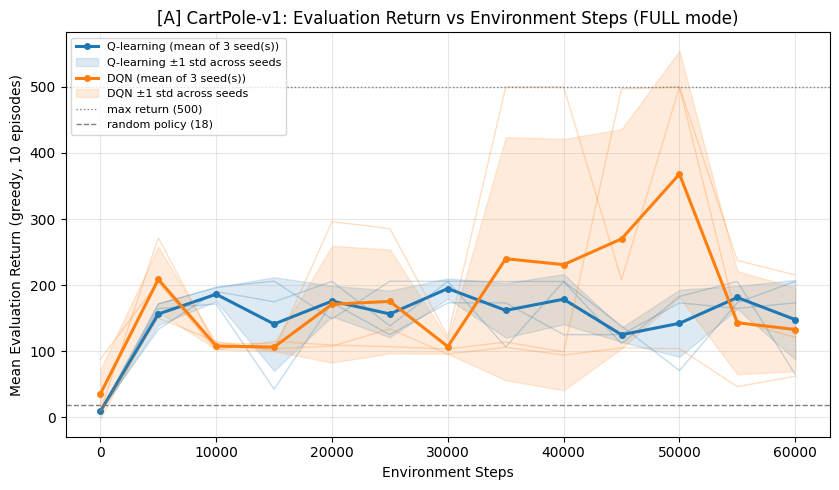

In [62]:
# [제공] 그래프 A — 환경 스텝에 따른 평가 평균 리턴
plot_eval_curves({"Q-learning": q_logs, "DQN": dqn_logs},
                 title=f"[A] CartPole-v1: Evaluation Return vs Environment Steps ({'FAST' if FAST_MODE else 'FULL'} mode)",
                 fname="fig_1_4_A_eval_return")

💾 그래프 저장: results/figures/fig_1_4_B_train_vs_eval.png


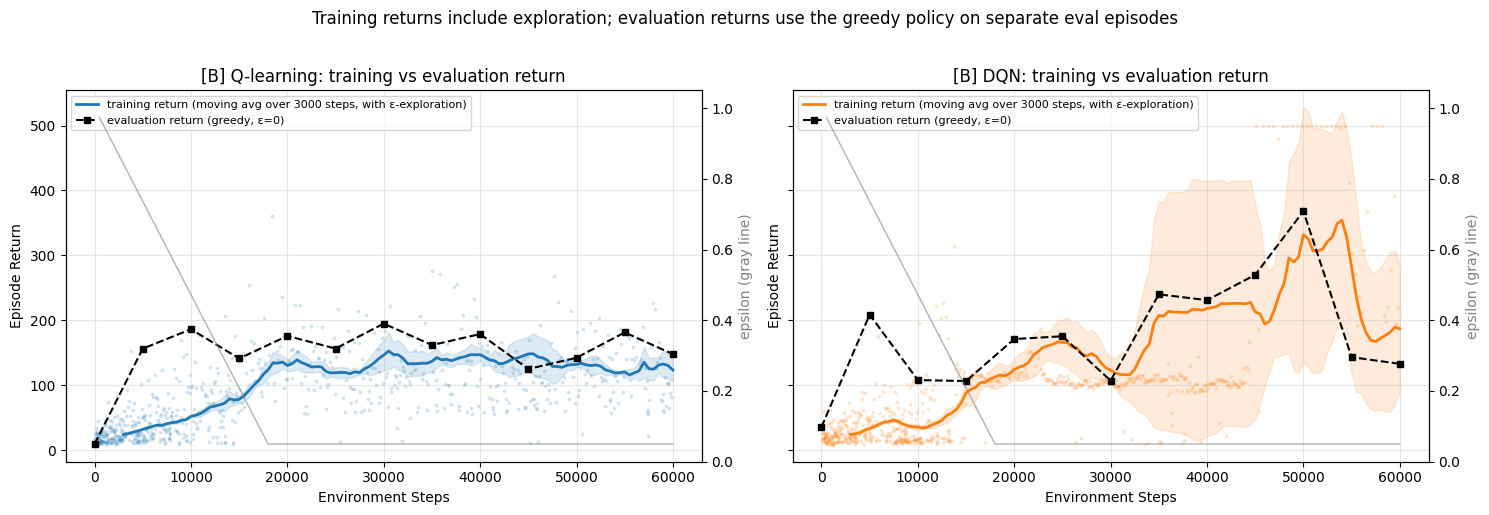

In [63]:
# [제공] 그래프 B — 학습 에피소드 리턴(탐험 포함) vs 평가 리턴(탐험 제외)
TRAIN_WINDOW = max(1_000, TOTAL_STEPS // 20)      # 이동 평균 창 크기 (스텝)
grid = np.arange(TRAIN_WINDOW, TOTAL_STEPS + 1, LOG_INTERVAL)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, logs) in zip(axes, {"Q-learning": q_logs, "DQN": dqn_logs}.items()):
    c = color_of(name)
    for lg in logs:   # 개별 학습 에피소드(점) — 첫 시드만 표시
        ax.scatter(lg["episode_end_steps"], lg["episode_returns"], s=3, color=c, alpha=0.15)
        break
    train_curves = np.array([training_curve_on_grid(lg, grid, TRAIN_WINDOW) for lg in logs])
    tr_mean = np.nanmean(train_curves, axis=0)
    ax.plot(grid, tr_mean, color=c, lw=2, label=f"training return (moving avg over {TRAIN_WINDOW} steps, with ε-exploration)")
    if len(logs) > 1:
        tr_std = np.nanstd(train_curves, axis=0)
        ax.fill_between(grid, tr_mean - tr_std, tr_mean + tr_std, color=c, alpha=0.15)
    steps, ev_mean, _ = aggregate_curves(logs)
    ax.plot(steps, ev_mean, color="black", ls="--", marker="s", ms=4, lw=1.5, label="evaluation return (greedy, ε=0)")
    ax2 = ax.twinx()
    ax2.plot(logs[0]["stat_steps"], logs[0]["epsilon"], color="gray", alpha=0.6, lw=1)
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("epsilon (gray line)", color="gray")
    ax.set_title(f"[B] {name}: training vs evaluation return")
    ax.set_xlabel("Environment Steps")
    ax.set_ylabel("Episode Return")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Training returns include exploration; evaluation returns use the greedy policy on separate eval episodes", y=1.02)
fig.tight_layout()
save_fig(fig, "fig_1_4_B_train_vs_eval")
plt.show()

💾 그래프 저장: results/figures/fig_1_4_C_dqn_loss.png


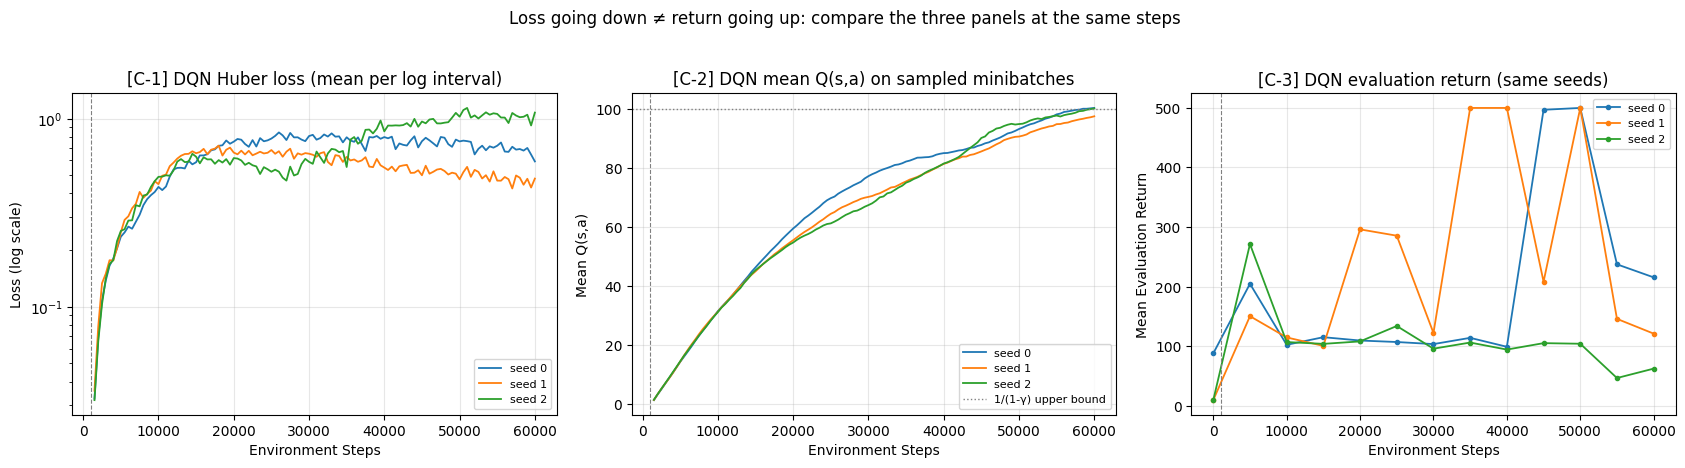

💾 그래프 저장: results/figures/fig_1_4_D_qlearning_td_error.png


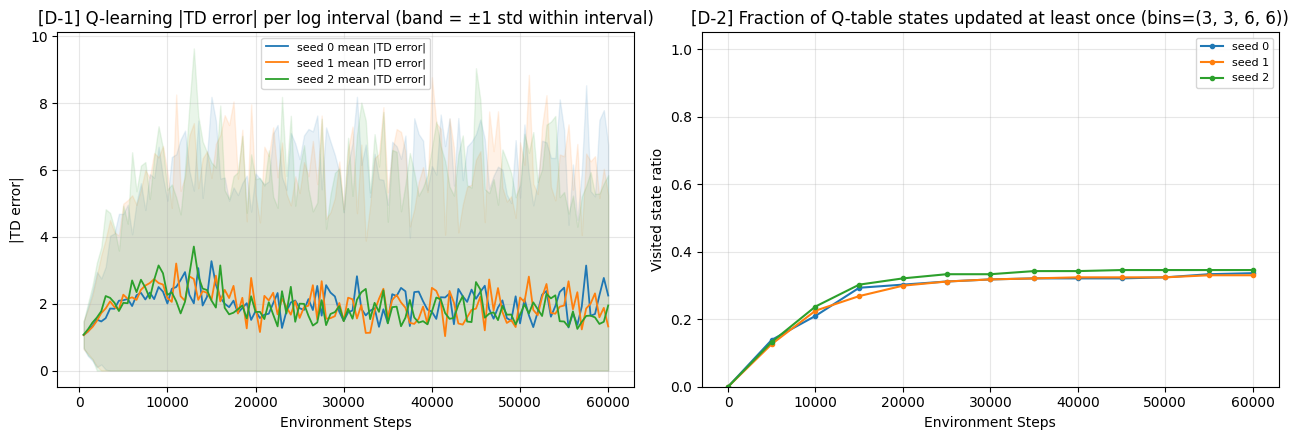

In [64]:
# [제공] 그래프 C — DQN Loss와 평균 Q(s,a), 그래프 D — Q-learning |TD error|와 방문 상태 비율
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for i, lg in enumerate(dqn_logs):
    axes[0].plot(lg["stat_steps"], lg["loss_mean"], color=PALETTE[i], lw=1.3, label=f"seed {lg['seed']}")
    axes[1].plot(lg["stat_steps"], lg["q_mean"], color=PALETTE[i], lw=1.3, label=f"seed {lg['seed']}")
    ax3 = axes[2]
    ax3.plot(lg["eval_steps"], lg["eval_mean"], color=PALETTE[i], marker="o", ms=3, lw=1.3, label=f"seed {lg['seed']}")
axes[0].set_yscale("log")
axes[0].set_title("[C-1] DQN Huber loss (mean per log interval)")
axes[0].set_ylabel("Loss (log scale)")
axes[1].set_title("[C-2] DQN mean Q(s,a) on sampled minibatches")
axes[1].set_ylabel("Mean Q(s,a)")
axes[1].axhline(1 / (1 - GAMMA), color="gray", ls=":", lw=1, label="1/(1-γ) upper bound")
axes[2].set_title("[C-3] DQN evaluation return (same seeds)")
axes[2].set_ylabel("Mean Evaluation Return")
for ax in axes:
    ax.axvline(DQN_CONFIG["learning_starts"], color="gray", ls="--", lw=0.8)
    ax.set_xlabel("Environment Steps")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Loss going down ≠ return going up: compare the three panels at the same steps", y=1.03)
fig.tight_layout()
save_fig(fig, "fig_1_4_C_dqn_loss")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, lg in enumerate(q_logs):
    m, s = np.array(lg["td_abs_mean"]), np.array(lg["td_abs_std"])
    axes[0].plot(lg["stat_steps"], m, color=PALETTE[i], lw=1.3, label=f"seed {lg['seed']} mean |TD error|")
    axes[0].fill_between(lg["stat_steps"], np.maximum(m - s, 0), m + s, color=PALETTE[i], alpha=0.1)
    axes[1].plot(lg["eval_steps"], lg["visited_ratio"], color=PALETTE[i], marker="o", ms=3, label=f"seed {lg['seed']}")
axes[0].set_title("[D-1] Q-learning |TD error| per log interval (band = ±1 std within interval)")
axes[0].set_ylabel("|TD error|")
axes[1].set_title(f"[D-2] Fraction of Q-table states updated at least once (bins={DEFAULT_BINS})")
axes[1].set_ylabel("Visited state ratio")
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.set_xlabel("Environment Steps")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_1_4_D_qlearning_td_error")
plt.show()

### ✍️ 관찰 문제 1.4 (기술블로그 "학습 곡선 비교" 섹션에 그대로 활용하세요)
반드시 그래프에서 읽은 **숫자(스텝, 리턴 값)**를 근거로 쓰세요. FAST_MODE 결과로는 답하지 마세요.
1. 그래프 A에서 두 알고리즘의 평가 리턴 차이가 **가장 컸던 학습 구간**은 어디이며, 그 차이는 대략 얼마인가? 학습 초반 · 중반 · 후반 중 어느 구간에서 순위가 바뀌었는가?(바뀌지 않았다면 그렇다고 쓰세요)
2. 그래프 B에서 학습 리턴과 평가 리턴은 어떻게 달랐는가? ε 곡선과 연결해 그 이유를 설명하시오.
3. 그래프 C에서 DQN loss의 추세와 평가 리턴의 추세는 일치했는가? 일치하지 않은 구간이 있다면 그 이유를 추론하시오.
4. 학습 곡선의 변동성(시드 간 음영 폭, 평가 리턴의 출렁임)이 큰 구간이 있었다면 그 원인으로 무엇을 의심할 수 있는가?

> ✍️ **답변 1:** 차이는 50,000 스텝에서 가장 컸다. 순위는 여러 번 바뀌어서, 10,000~30,000 스텝은 Q-learning이, 35,000~50,000 스텝은 DQN이 앞섰고 마지막에는 다시 Q-learning이 앞섰다
> ✍️ **답변 2:** ε이 높은 초반 약 18,000 스텝까지는 무작위 행동이 많아 학습 리턴이 100 아래로 평가 리턴보다 낮았다. ε이 0.05가 된 뒤에는 차이가 줄었다.
>
> ✍️ **답변 3:** 일치하지 않았다. loss는 10,000 스텝 이후 0.5~1.0에서 평평했는데, 평가 리턴은 시드 1 기준 122.0 -> 500.0 -> 208.1로 크게 출렁였다. Q값이 계속 커지고 목표값도 같이 움직여서 loss로는 성능을 알 수 없다.
>
> ✍️ **답변 4:** DQN의 35,000~55,000 스텝 구간이 가장 컸다(50,000 스텝에서 시드 0, 1은 500.0, 시드 2는 103.9). 시드마다 좋은 정책을 찾는 시점이 다르고, Target Network가 통째로 바뀌며 정책이 급변하는 것을 의심할 수 있다.

## 문제 1.5 성능 비교 및 정량적 평가 — TODO 14
학습이 끝난 **최종 정책**을 주기적 평가와 **다른 초기 상태 집합**(`FINAL_EVAL_SEED_BASE`)에서 `FINAL_EVAL_EPISODES`번 평가하고, 학습 과정 전체에서 아래 지표를 계산합니다.

| 지표 | 정의 | 무엇을 보여주는가 |
|---|---|---|
| `final_eval_mean` / `final_eval_std` | 최종 정책의 평가 리턴 평균 / 표준편차 | 최종 성능과 초기 상태에 따른 편차 |
| `best_eval_mean` / `best_eval_step` | 주기적 평가 평균의 최댓값과 그 시점 | 학습 중 도달한 최고 성능 (최종 성능과 다를 수 있음) |
| `early_train_return` / `late_train_return` | 전체 스텝의 처음 / 마지막 20% 구간에서 끝난 학습 에피소드 평균 리턴 | 학습 초반과 후반의 차이 |
| `train_improvement` | `late - early` | 학습 추세 |
| `eval_volatility` | 연속된 평가 평균 간 차이(`np.diff`)의 표준편차 | 학습 곡선이 얼마나 출렁이는가 |
| `late_train_std` | 마지막 20% 구간 학습 리턴의 표준편차 | 학습 후반의 변동성 |

> 최고 평가 리턴(`best_eval_mean`)은 여러 시점 중 최댓값을 고른 것이므로 낙관적으로 편향되어 있습니다. 최종 비교는 `final_eval_mean`을 우선으로 하세요.

In [65]:
def compute_summary_metrics(log, final_eval, frac=0.2):
    # TODO 14: 한 번의 학습(하나의 알고리즘 × 하나의 시드)에 대한 평가 지표를 계산하세요.
    #
    # 이 함수의 목적: 위 표의 지표를 dict로 반환
    # 입력:
    #   log        — train_q_learning / train_dqn이 반환한 로그
    #                (사용할 키: "total_steps", "eval_steps", "eval_mean",
    #                 "episode_end_steps", "episode_returns")
    #   final_eval — evaluate_policy(...)의 반환 dict (최종 정책 평가 결과)
    #   frac       — 초반/후반 구간 비율 (기본 0.2 = 20%)
    # 반환: dict 키 = "final_eval_mean", "final_eval_std", "best_eval_mean", "best_eval_step",
    #                 "early_train_return", "late_train_return", "train_improvement",
    #                 "eval_volatility", "late_train_std"
    # 주의:
    # - 초반 구간: episode_end_steps <= total_steps * frac 인 에피소드
    #   후반 구간: episode_end_steps >  total_steps * (1 - frac) 인 에피소드
    # - 해당 구간에 끝난 에피소드가 없으면 np.nan으로 둡니다.
    #   (학습이 잘 되어 에피소드가 500 스텝씩 길어지면 짧은 구간에 끝난 에피소드가 없을 수 있습니다)
    total = log["total_steps"]
    eval_steps = np.asarray(log["eval_steps"])
    eval_mean = np.asarray(log["eval_mean"], dtype=float)
    ends = np.asarray(log["episode_end_steps"])
    rets = np.asarray(log["episode_returns"], dtype=float)

    early = rets[ends <= total * frac]
    late = rets[ends > total * (1 - frac)]
    early_ret = float(early.mean()) if len(early) else np.nan
    late_ret = float(late.mean()) if len(late) else np.nan
    best = int(np.argmax(eval_mean))
    return {
        "final_eval_mean": float(final_eval["mean"]),
        "final_eval_std": float(final_eval["std"]),
        "best_eval_mean": float(eval_mean[best]),
        "best_eval_step": int(eval_steps[best]),
        "early_train_return": early_ret,
        "late_train_return": late_ret,
        "train_improvement": late_ret - early_ret,
        "eval_volatility": float(np.std(np.diff(eval_mean))) if len(eval_mean) > 1 else np.nan,
        "late_train_std": float(late.std()) if len(late) else np.nan,
    }


# [제공] TODO 14 테스트
_log = {"total_steps": 100, "eval_steps": [0, 50, 100], "eval_mean": [10.0, 30.0, 20.0],
        "episode_end_steps": [10, 20, 50, 85, 100], "episode_returns": [10.0, 10.0, 30.0, 35.0, 15.0]}
_m = compute_summary_metrics(_log, {"mean": 25.0, "std": 5.0})
assert np.isclose(_m["final_eval_mean"], 25.0) and np.isclose(_m["final_eval_std"], 5.0)
assert np.isclose(_m["best_eval_mean"], 30.0) and _m["best_eval_step"] == 50
assert np.isclose(_m["early_train_return"], 10.0) and np.isclose(_m["late_train_return"], 25.0)
assert np.isclose(_m["train_improvement"], 15.0)
assert np.isclose(_m["eval_volatility"], np.std([20.0, -10.0]))
assert np.isclose(_m["late_train_std"], 10.0)
print("✅ TODO 14 테스트 통과")

✅ TODO 14 테스트 통과


■ 시드별 지표


final_eval_mean  final_eval_std  best_eval_mean  \
algo       seed                                                    
Q-learning 0              127.30           30.60           173.1   
           1              145.90           30.13           205.5   
           2              106.10           57.48           206.0   
DQN        0              219.65           24.81           500.0   
           1              122.25            4.55           500.0   
           2               63.20           66.30           271.3   

                 best_eval_step  early_train_return  late_train_return  \
algo       seed                                                          
Q-learning 0              20000               37.34             120.81   
           1              20000               36.58             117.54   
           2              15000               38.81             138.18   
DQN        0              50000               33.03             387.58   
           1              35000               32.34             213.14   
           2               5000               35.93              71.54   

                 train_improvement  eval_volatility  late_train_std  
algo       seed                                                      
Q-learning 0                 83.47            73.59           44.50  
           1                 80.96            74.12           55.20  
           2                 99.38            75.04           56.70  
DQN        0                354.55           144.73          126.21  
           1                180.79           209.14          154.48  
           2                 35.61            92.03           69.34

💾 표 저장: results/tables/table_1_5_per_seed.csv
■ 알고리즘별 요약 (mean = 시드 평균, std = 시드 간 표준편차)


final_eval_mean        final_eval_std        best_eval_mean  \
                      mean    std           mean    std           mean   
algo                                                                     
DQN                 135.03  79.00          31.89  31.48         423.77   
Q-learning          126.43  19.91          39.40  15.66         194.87   

                   best_eval_step           early_train_return        \
               std           mean       std               mean   std   
algo                                                                   
DQN         132.04       30000.00  22912.88              33.77  1.91   
Q-learning   18.85       18333.33   2886.75              37.58  1.13   

           late_train_return         train_improvement          \
                        mean     std              mean     std   
algo                                                             
DQN                   224.09  158.30            190.32  159.68   
Q-learning            125.51   11.09             87.94    9.99   

           eval_volatility        late_train_std         
                      mean    std           mean    std  
algo                                                     
DQN                 148.63  58.65         116.68  43.36  
Q-learning           74.25   0.73          52.13   6.65

💾 표 저장: results/tables/table_1_5_summary.csv
💾 그래프 저장: results/figures/fig_1_5_final_eval.png


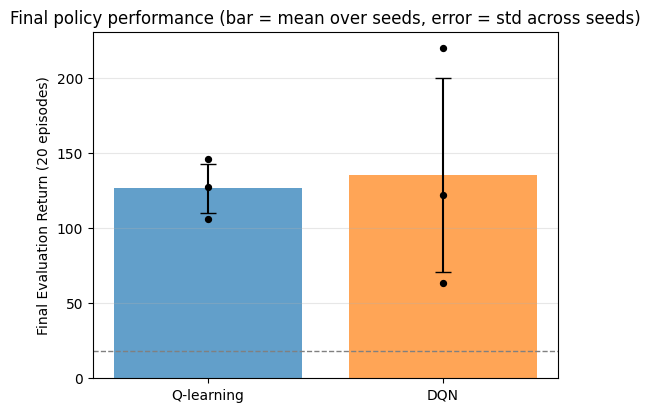

In [66]:
# [제공] 최종 정책 평가 + 시드별 / 알고리즘별 지표 표
def build_final_policy(log):
    """로그에 저장된 최종 Q-table 또는 신경망 가중치로 greedy 정책을 복원합니다."""
    if log["algo"] == "Q-learning":
        return make_q_policy(log["final_q_table"], build_bins_list(log["n_bins"]))
    net = QNetwork(log["obs_dim"], log["n_actions"], log["config"]["hidden_dim"]).to(DEVICE)
    net.load_state_dict(log["final_state_dict"])
    net.eval()
    def policy(obs):
        with torch.no_grad():
            return int(net(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)).argmax(dim=1).item())
    return policy


rows = []
for lg in q_logs + dqn_logs:
    fe = evaluate_policy(build_final_policy(lg), n_episodes=FINAL_EVAL_EPISODES, seed_base=FINAL_EVAL_SEED_BASE)
    rows.append({"algo": lg["algo"], "seed": lg["seed"], **compute_summary_metrics(lg, fe)})
per_seed_df = pd.DataFrame(rows).set_index(["algo", "seed"]).round(2)
print("■ 시드별 지표")
display(per_seed_df)
save_table(per_seed_df, "table_1_5_per_seed")

summary_df = per_seed_df.groupby(level="algo").agg(["mean", "std"]).round(2)
print("■ 알고리즘별 요약 (mean = 시드 평균, std = 시드 간 표준편차)")
display(summary_df)
save_table(summary_df, "table_1_5_summary")

# 최종 평가 막대그래프 (시드 평균 ± 시드 간 표준편차, 점 = 개별 시드)
fig, ax = plt.subplots(figsize=(6, 4.5))
for i, algo in enumerate(["Q-learning", "DQN"]):
    vals = per_seed_df.loc[algo, "final_eval_mean"].values
    ax.bar(i, vals.mean(), yerr=vals.std() if len(vals) > 1 else None, color=color_of(algo), alpha=0.7, capsize=6)
    ax.scatter(np.full(len(vals), i), vals, color="black", zorder=3, s=18)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Q-learning", "DQN"])
ax.set_ylabel(f"Final Evaluation Return ({FINAL_EVAL_EPISODES} episodes)")
ax.set_title("Final policy performance (bar = mean over seeds, error = std across seeds)")
ax.axhline(RANDOM_BASELINE, color="gray", ls="--", lw=1)
ax.grid(alpha=0.3, axis="y")
save_fig(fig, "fig_1_5_final_eval")
plt.show()

### ✍️ 해석 문제 1.5
표와 그래프의 숫자를 인용해 답하세요. "DQN이 더 좋다"처럼 결론만 쓰지 말고, **어떤 지표로 그렇게 판단했는지와 시드 간 차이를 고려했는지**를 함께 쓰세요.
1. 어느 알고리즘이 더 높은 최종 보상을 얻었는가? 시드 간 표준편차를 고려해도 그 차이는 의미 있어 보이는가?
2. 어느 알고리즘의 학습 곡선이 더 안정적이었는가? (`eval_volatility`, `late_train_std`, 그래프 A의 음영 폭)
3. 두 방법의 성능 차이는 무엇에서 발생했다고 생각하는가? 가설을 세우고, 그 가설을 확인하려면 어떤 추가 실험이 필요한지도 쓰시오.
4. Tabular Q-learning의 상태 이산화가 결과에 어떤 영향을 주었는가? (그래프 D-2의 방문 상태 비율도 참고)
5. DQN이 신경망을 사용한다는 이유만으로 더 좋은 결과를 보장할 수 있는가?

> ✍️ **답변 1:** 최종 평가는 DQN 135.03, Q-learning 126.43이다. DQN의 시드 간 표준편차가 79.0이라 이 차이는 의미 있다고 볼 수 없다.
>
> ✍️ **답변 2:** Q-learning이 더 안정적이었다. eval_volatility는 74.25 vs 148.63, late_train_std는 52.13 vs 116.68이고 음영도 DQN이 훨씬 넓었다.
>
> ✍️ **답변 3:** DQN은 500점까지 갈 수 있지만 불안정해서 유지하지 못했고, Q-learning은 이산화 때문에 200점 근처에서 막혔다고 본다. DQN의 학습률을 낮추거나 Target Network 업데이트 간격을 늘려 붕괴가 줄어드는지 확인하면 된다.
>
> ✍️ **답변 4:** 방문 상태 비율이 0.34에서 멈췄고 최고 평가도 173~206에서 막혔다. 서로 다른 상태가 같은 칸에 묶여 성능에 천장이 생긴 것으로 보인다.
>
> ✍️ **답변 5:** 보장할 수 없다. 최종 성능은 비슷했고 변동성은 DQN이 2배였으며, 학습 시간도 약 16배 걸렸다.

## 문제 1.6 추가 실험: 상태 이산화 구간 변경 — TODO 15
1.1에서 만든 `make_bins` · `discretize_state`와 1.2의 `train_q_learning`을 그대로 사용해, **구간 수만 바꾸고 나머지 조건(예산, α, ε 스케줄, 시드, 평가)은 동일하게** 유지한 채 Q-learning을 다시 학습합니다.

- **TODO 15-a:** `"coarse"`(적은 구간), `"default"`(기본 = `DEFAULT_BINS`), `"fine"`(많은 구간) 세 설정을 직접 정의하세요. 어떤 변수에 구간을 더 줄지 · 덜 줄지 스스로 결정하고, 그 이유를 아래 답변에 쓰세요.
- **TODO 15-b:** 각 설정의 Q-table 크기(원소 수)를 계산하는 함수를 작성하세요.

> `"default"` 설정의 결과는 1.4에서 이미 학습한 `q_logs`를 재사용해 계산 비용을 줄입니다.

In [67]:
# TODO 15-a: 비교할 이산화 설정 3가지를 정의하세요.
#
# 목적: 구간 수(상태 공간의 해상도)만 바꿨을 때 성능 · 학습 속도 · 변동성이 어떻게 달라지는지 비교
# 형식: {"이름": (위치 구간수, 속도 구간수, 각도 구간수, 각속도 구간수)}
# 조건: "coarse"의 상태 수 < "default"의 상태 수 < "fine"의 상태 수
#       각 원소는 1 이상의 정수 (1 = 해당 변수를 무시)
BIN_CONFIGS = {
    "coarse": (1,1,3,3),
    "default": DEFAULT_BINS,
    "fine": (6,6,12,12),
}


def q_table_size(n_bins, n_actions=2):
    # TODO 15-b: Q-table의 원소 수를 계산하세요.
    #
    # 이 함수의 목적: 상태 수(= 각 차원 구간 수의 곱) × 행동 수
    # 입력: n_bins (튜플), n_actions (int)
    # 반환: int
    return int(np.prod(n_bins))*n_actions


# [제공] TODO 15 테스트
assert set(BIN_CONFIGS) == {"coarse", "default", "fine"}, "coarse / default / fine 세 설정을 모두 정의하세요."
assert BIN_CONFIGS["default"] == DEFAULT_BINS
assert q_table_size((3, 3, 6, 6)) == 648 and q_table_size((1, 1, 1, 1), 2) == 2
_sizes = {k: q_table_size(v) for k, v in BIN_CONFIGS.items()}
assert _sizes["coarse"] < _sizes["default"] < _sizes["fine"], f"상태 수 순서를 확인하세요: {_sizes}"
for name, bins in BIN_CONFIGS.items():
    print(f"{name:>8}: bins={bins} → states={int(np.prod(bins)):>6}, Q-table entries={q_table_size(bins):>6}")
print("✅ TODO 15 테스트 통과")

  coarse: bins=(1, 1, 3, 3) → states=     9, Q-table entries=    18
 default: bins=(3, 3, 6, 6) → states=   324, Q-table entries=   648
    fine: bins=(6, 6, 12, 12) → states=  5184, Q-table entries= 10368
✅ TODO 15 테스트 통과


[coarse] bins=(1, 1, 3, 3) 학습 시작
    완료 — 소요 55.7s
[default] 1.4의 학습 결과를 재사용합니다.
[fine] bins=(6, 6, 12, 12) 학습 시작
    완료 — 소요 52.6s
💾 그래프 저장: results/figures/fig_1_6_bins_eval_return.png


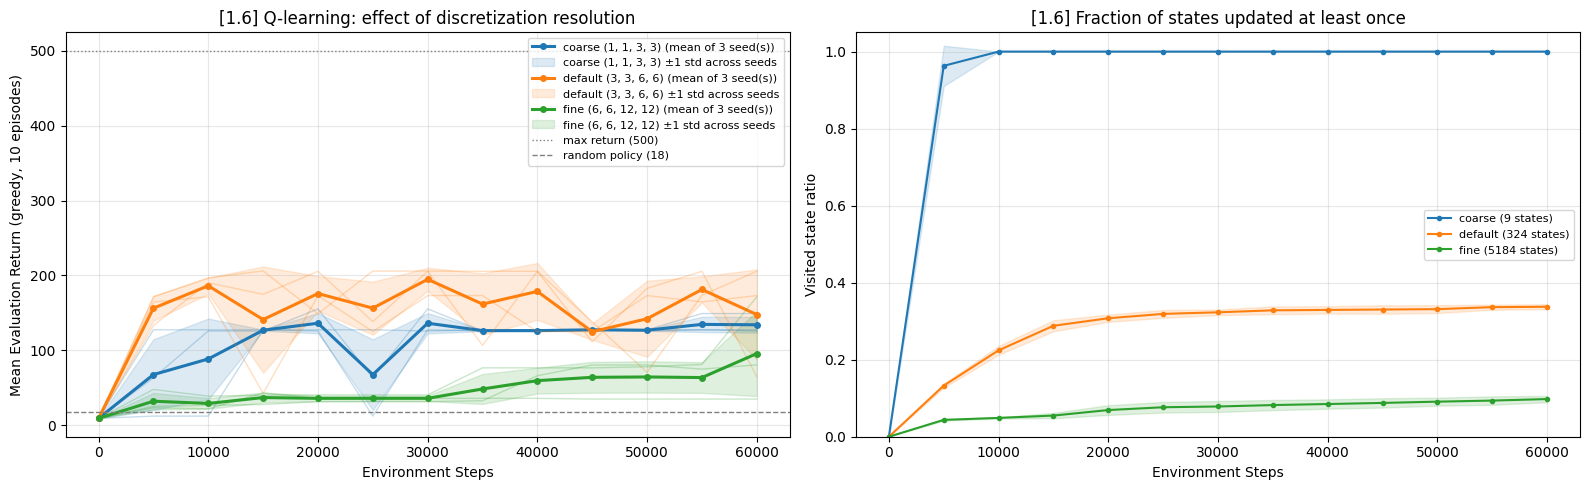

final_eval_mean        final_eval_std  \
                                                  mean    std           mean   
config  bins           q_table_entries                                         
coarse  (1, 1, 3, 3)   18                       137.15  16.14           7.33   
default (3, 3, 6, 6)   648                      126.43  19.91          39.40   
fine    (6, 6, 12, 12) 10368                    101.03  26.24          90.77   

                                              best_eval_mean         \
                                          std           mean    std   
config  bins           q_table_entries                                
coarse  (1, 1, 3, 3)   18                2.06         136.70  16.11   
default (3, 3, 6, 6)   648              15.66         194.87  18.85   
fine    (6, 6, 12, 12) 10368            36.29          98.37  65.97   

                                       train_improvement         \
                                                    mean    std   
config  bins           q_table_entries                            
coarse  (1, 1, 3, 3)   18                          61.29  10.13   
default (3, 3, 6, 6)   648                         87.94   9.99   
fine    (6, 6, 12, 12) 10368                       42.58   8.24   

                                       eval_volatility         \
                                                  mean    std   
config  bins           q_table_entries                          
coarse  (1, 1, 3, 3)   18                        44.63  12.63   
default (3, 3, 6, 6)   648                       74.25   0.73   
fine    (6, 6, 12, 12) 10368                     14.88  10.72   

                                       final_visited_ratio        
                                                      mean   std  
config  bins           q_table_entries                            
coarse  (1, 1, 3, 3)   18                             1.00  0.00  
default (3, 3, 6, 6)   648                            0.34  0.01  
fine    (6, 6, 12, 12) 10368                          0.10  0.01

💾 표 저장: results/tables/table_1_6_bins.csv


In [68]:
# [제공] 이산화 설정별 Q-learning 재학습
bin_logs = {}
for name, bins in BIN_CONFIGS.items():
    if tuple(bins) == tuple(DEFAULT_BINS):
        bin_logs[name] = q_logs                       # 1.4 결과 재사용 (같은 조건)
        print(f"[{name}] 1.4의 학습 결과를 재사용합니다.")
        continue
    print(f"[{name}] bins={bins} 학습 시작")
    bin_logs[name] = [train_q_learning(seed, n_bins=bins, verbose=False) for seed in SEEDS]
    print(f"    완료 — 소요 {sum(lg['wall_time_sec'] for lg in bin_logs[name]):.1f}s")

with open(os.path.join(LOG_DIR, "bins_logs.pkl"), "wb") as f:
    pickle.dump(bin_logs, f)

# 그래프: 설정별 평가 곡선 + 방문 상태 비율
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_eval_curves({f"{k} {BIN_CONFIGS[k]}": v for k, v in bin_logs.items()},
                 title="[1.6] Q-learning: effect of discretization resolution", fname=None, ax=axes[0])
for i, (name, logs) in enumerate(bin_logs.items()):
    steps, m, sd = aggregate_curves(logs, "eval_steps", "visited_ratio")
    axes[1].plot(steps, m, color=PALETTE[i], marker="o", ms=3, label=f"{name} ({int(np.prod(BIN_CONFIGS[name]))} states)")
    if len(logs) > 1:
        axes[1].fill_between(steps, m - sd, m + sd, color=PALETTE[i], alpha=0.15)
axes[1].set_title("[1.6] Fraction of states updated at least once")
axes[1].set_xlabel("Environment Steps")
axes[1].set_ylabel("Visited state ratio")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_1_6_bins_eval_return")
plt.show()

# 표: 설정별 지표
rows = []
for name, logs in bin_logs.items():
    for lg in logs:
        fe = evaluate_policy(build_final_policy(lg), n_episodes=FINAL_EVAL_EPISODES, seed_base=FINAL_EVAL_SEED_BASE)
        m = compute_summary_metrics(lg, fe)
        rows.append({"config": name, "bins": str(BIN_CONFIGS[name]), "q_table_entries": q_table_size(BIN_CONFIGS[name]),
                     "seed": lg["seed"], "final_visited_ratio": lg["visited_ratio"][-1], **m})
bins_df = pd.DataFrame(rows)
bins_summary = (bins_df.groupby(["config", "bins", "q_table_entries"])
                [["final_eval_mean", "final_eval_std", "best_eval_mean", "train_improvement", "eval_volatility", "final_visited_ratio"]]
                .agg(["mean", "std"]).round(2).sort_index(level="q_table_entries"))
display(bins_summary)
save_table(bins_summary, "table_1_6_bins")

### ✍️ 해석 문제 1.6
1. 각 설정의 Q-table 크기와 최종 평가 성능, 학습 곡선의 추세(빠르게 오르는지 · 느리게 오르는지 · 정체되는지), 시드 간 변동성을 비교해 정리하시오. 자신이 coarse / fine 설정을 그렇게 설계한 이유도 함께 쓰시오.
2. **"상태를 더 세밀하게 구분하면 항상 좋은 결과가 나타나는가? 이 실험 결과를 바탕으로 DQN의 필요성을 설명하시오."**

> ✍️ **답변 1:** coarse(18칸)는 빨리 오르지만 약 130에서 정체됐고 최종 137.15였다. default(648칸)는 최고 194.87까지 올랐지만 출렁임이 컸고 최종 126.43, fine(10,368칸)은 방문 비율 0.10으로 가장 느려 최종 101.03이었다. coarse는 각도와 각속도만 남겼고, fine은 네 변수 모두 기본의 2배로 나눴다.
>
> ✍️ **답변 2:** 아니다. fine은 60,000 스텝으로도 칸의 10%만 방문해 default보다 낮았다. 표 방식은 세밀할수록 칸당 경험이 부족해지는데, DQN은 비슷한 상태끼리 일반화하므로 이 문제를 피할 수 있다.

## 문제 1.7 종합 해석
지금까지의 표 · 그래프를 근거로 **문장형**으로 답하세요. 정해진 정답은 없습니다. 여러분이 측정한 숫자와 그에 대한 해석이 평가 대상입니다. (기술블로그의 결론 섹션으로 활용하세요.)

1. Tabular Q-learning과 DQN의 가장 본질적인 차이는 무엇인가?
2. 이번 실험에서 두 알고리즘의 성능 차이가 나타난 이유는 무엇인가? (차이가 없었다면 그 이유는?)
3. Experience Replay와 Target Network는 각각 어떤 문제를 해결하는가?
4. 학습 곡선(그래프 A · B)과 최종 평가 결과(1.5 표)가 서로 다른 결론을 시사하는가?
5. 실험의 한계점은 무엇인가?
6. 실험을 다시 진행한다면 어떤 조건을 추가로 통제하고 싶은가?

> ✍️ **답변 1:** Q값을 저장하는 방식이다. Q-learning은 칸마다 따로 저장하는 표이고, DQN은 신경망으로 근사해 비슷한 상태끼리 일반화한다.
>
> ✍️ **답변 2:** 최종 평가는 135.03 vs 126.43으로 사실상 차이가 없었다. DQN은 500점에 도달했다가 무너졌고, Q-learning은 이산화 한계로 200점 근처에서 막혔기 때문이다.
>
> ✍️ **답변 3:** Experience Replay는 연속된 경험의 상관관계를 줄이고 데이터를 재사용하게 한다. Target Network는 목표값이 업데이트마다 같이 움직이는 문제를 줄인다.
>
> ✍️ **답변 4:** 다른 결론을 시사한다. 학습 곡선에서는 DQN이 50,000 스텝에 368.0으로 크게 앞섰지만 최종 평가는 비슷했다.
> ✍️ **답변 5:** 시드가 3개뿐이고 DQN은 시드 간 차이가 매우 컸다. 계산량이 통제되지 않았고, 마지막 시점 하나로 최종 성능을 판단했다.
>
> ✍️ **답변 6:** 시드를 늘리고 후반 여러 시점의 평균으로 평가하고 싶다. 두 알고리즘의 계산량도 맞추고 싶다.

# 2. 심화 과제 (선택): LunarLander-v3에서 PPO 하이퍼파라미터 튜닝
> 🔖 **이 파트는 선택 과제입니다.** 필수 과제를 모두 마친 뒤 진행하세요. 수행하지 않을 경우 이 파트의 셀은 실행하지 않아도 되며(아래 `RUN_ADVANCED = False`), 3. 회고와 4. 생성형 AI 활용 기록은 반드시 작성하세요.

**목표는 최고 점수가 아니라**, `learning_rate` · `clip_range` · `n_steps`를 하나씩 바꿨을 때 **학습 속도 · 안정성 · 최종 성능**이 어떻게 달라지는지를 해석하는 것입니다.

### 2.0 설치 및 의존성 확인
`LunarLander-v3`는 Box2D 물리 엔진이 필요합니다. 설치가 실패하면 아래 순서로 해결해 보세요.
1. `!pip install swig` 후 `!pip install "gymnasium[box2d]>=1.0"` 재시도 (Box2D 빌드에 SWIG가 필요할 수 있음)
2. 그래도 실패하면 `!apt-get install -y swig build-essential python3-dev` 후 재시도
3. 설치 후 `ImportError`가 계속되면 **런타임 → 세션 다시 시작** 후 0.2 셀부터 다시 실행
4. `LunarLander-v3`를 찾을 수 없다는 오류는 Gymnasium 1.0 미만 버전 때문입니다 → `!pip install -U "gymnasium[box2d]>=1.0"`

설치 문제로 진행이 불가능하면 오류 메시지와 시도한 방법을 2.4 보고서의 "실험 한계"에 기록하세요. 실행하지 않은 실험의 결과를 추정해 쓰지 마세요.

In [ ]:
# [제공] 심화 과제 설치 및 의존성 확인
RUN_ADVANCED = False    # 심화 과제를 수행하려면 True로 바꾸세요.

if RUN_ADVANCED:
    !pip install -q swig
    !pip install -q "gymnasium[box2d]>=1.0" "stable-baselines3>=2.3"

PPO_AVAILABLE = False
if RUN_ADVANCED:
    try:
        import stable_baselines3
        from stable_baselines3 import PPO
        from stable_baselines3.common.env_util import make_vec_env
        _probe = gym.make("LunarLander-v3")
        _probe.reset(seed=0)
        _probe.close()
        PPO_AVAILABLE = True
        print(f"✅ LunarLander-v3 사용 가능 | Stable-Baselines3 {stable_baselines3.__version__} | Gymnasium {gym.__version__}")
    except Exception as e:
        print(f"❌ 심화 과제 의존성 확인 실패: {type(e).__name__}: {e}")
        print("   위 Markdown 셀의 해결 방법을 시도한 뒤 다시 실행하세요. 필수 과제 결과에는 영향이 없습니다.")
else:
    print("심화 과제를 건너뜁니다 (RUN_ADVANCED = False).")

## 문제 2.1 LunarLander 환경 이해와 PPO 복습
**LunarLander-v3** — 착륙선을 두 깃발 사이의 착륙 지점에 부드럽게 착륙시키는 환경입니다.

| 항목 | 내용 |
|---|---|
| 관측 (8차원) | x, y 위치, x, y 속도, 각도, 각속도, 왼쪽 · 오른쪽 다리 접지 여부(0/1) |
| 행동 (**이산 4개**) | 0: 아무것도 안 함, 1: 왼쪽 엔진, 2: 메인 엔진, 3: 오른쪽 엔진 |
| 보상 | 착륙 지점 접근 · 감속 시 +, 멀어지면 −, 다리 접지 +10, 엔진 분사마다 소량 −, 추락 −100, 안전 착지 +100 |
| 종료 | 추락 또는 착지 후 정지 시 `terminated`, 1000 스텝 도달 시 `truncated` |
| 참고 기준 | 에피소드 리턴 200 이상이면 "해결"로 간주 |

> `gym.make("LunarLander-v3", continuous=True)`로 **연속 행동 버전**(엔진 출력을 실수로 제어)도 사용할 수 있지만, 이 과제는 기본 **이산 행동 버전**을 사용합니다.

### PPO (Proximal Policy Optimization) 복습
- **Actor-Critic 구조:** Actor $\pi_\theta(a\mid s)$는 행동 확률을, Critic $V_\phi(s)$는 상태 가치를 출력합니다. Critic의 가치 추정으로 **Advantage** $\hat{A}_t$(GAE)를 계산해 Actor의 업데이트 방향을 정합니다.
- **On-policy rollout:** 현재 정책으로 `n_steps`만큼 데이터를 모은 뒤, 그 데이터로 `n_epochs`번 미니배치 업데이트를 하고 **버립니다**. (DQN의 Replay Buffer와 대조적)
- **Clipped objective:** 확률 비율 $r_t(\theta) = \dfrac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_\text{old}}(a_t\mid s_t)}$가 $[1-\epsilon, 1+\epsilon]$을 벗어나면 이득을 더 주지 않아 한 번에 정책이 너무 크게 바뀌는 것을 막습니다.

$$
L^{\text{CLIP}}(\theta) = \mathbb{E}_t\left[\min\left(r_t(\theta)\hat{A}_t,\ \text{clip}\big(r_t(\theta), 1-\epsilon, 1+\epsilon\big)\hat{A}_t\right)\right]
$$

| 하이퍼파라미터 | 의미 | 예상되는 영향 (가설 — 실험으로 확인할 것) |
|---|---|---|
| `learning_rate` | 옵티마이저 스텝 크기 | 크면 빠르지만 불안정, 작으면 안정적이지만 느림 |
| `clip_range` ($\epsilon$) | 한 번의 업데이트에서 허용하는 정책 변화 폭 | 좁으면 보수적, 넓으면 공격적 |
| `n_steps` | 업데이트 1회당 수집하는 rollout 길이 (환경 1개 기준) | 길면 advantage 추정이 안정적이지만 업데이트 빈도가 낮음 |

In [ ]:
# [제공] LunarLander 환경 정보 및 PPO 실험 설정
if PPO_AVAILABLE:
    PPO_ENV_ID = "LunarLander-v3"
    _env = gym.make(PPO_ENV_ID)
    print("Observation Space:", _env.observation_space)
    print("Action Space     :", _env.action_space)
    print("max_episode_steps:", _env.spec.max_episode_steps)
    _env.close()

    if FAST_MODE:
        PPO_SEEDS = [0]
        PPO_TOTAL_STEPS = 20_000       # 코드 점검용 — 이 예산으로는 의미 있는 학습이 일어나지 않습니다.
        PPO_EVAL_INTERVAL = 5_000
        PPO_EVAL_EPISODES = 3
    else:
        PPO_SEEDS = [0]                # 시간이 허락하면 [0, 1, 2]로 늘리세요 (비용 3배)
        PPO_TOTAL_STEPS = 200_000      # 설정당 예산. LunarLander를 '해결'하기에는 부족할 수 있습니다.
        PPO_EVAL_INTERVAL = 20_000
        PPO_EVAL_EPISODES = 10
    PPO_EVAL_SEED_BASE = 30_000

    PPO_BASE = dict(learning_rate=3e-4, clip_range=0.2, n_steps=1024)     # 기준(baseline) 설정
    PPO_FIXED = dict(batch_size=64, n_epochs=4, gamma=0.999, gae_lambda=0.98, ent_coef=0.01)  # 모든 실험에서 고정
    print("\nPPO 기준 설정:", PPO_BASE)
    print("PPO 고정 설정:", PPO_FIXED, "| 병렬 환경 수: 1 (n_steps = 업데이트 1회당 수집하는 전체 전이 수)")
    print(f"설정당 예산: {PPO_TOTAL_STEPS} env steps × 시드 {PPO_SEEDS} | 평가: {PPO_EVAL_INTERVAL} 스텝마다 {PPO_EVAL_EPISODES} 에피소드")

## 문제 2.2 기본 PPO 모델 학습 — TODO 16
Stable-Baselines3의 `PPO`로 기준(baseline) 모델을 만들고 학습합니다. 학습 · 평가 루프(`train_and_evaluate_ppo`)는 제공되며, 모델을 생성하는 부분만 구현합니다.
- 학습 환경과 평가 환경은 분리되어 있고, 평가는 `deterministic=True`(탐험 없는 행동)로 수행합니다.
- `model.learn()`은 rollout(`n_steps`) 단위로 끝나므로 평가 시점이 `PPO_EVAL_INTERVAL`의 배수에서 조금씩 어긋날 수 있습니다. x축에는 실제 학습 스텝(`model.num_timesteps`)을 사용합니다.

In [ ]:
# 약 7분 소요(로컬 환경별 상이)
def build_ppo_model(env, learning_rate, clip_range, n_steps, seed):
    # TODO 16: Stable-Baselines3 PPO 모델을 생성하세요.
    #
    # 이 함수의 목적:
    # - 실험할 세 하이퍼파라미터(learning_rate, clip_range, n_steps)와 seed를 반영한 PPO 객체 생성
    # - 정책: "MlpPolicy" (Actor와 Critic 모두 MLP)
    # - 나머지 하이퍼파라미터는 모든 실험에서 같도록 PPO_FIXED를 그대로 전달 (**PPO_FIXED)
    # - verbose=0 (로그 과다 출력 방지), device="cpu"
    #
    # 입력: env (학습용 VecEnv), learning_rate (float), clip_range (float), n_steps (int), seed (int)
    # 반환: stable_baselines3.PPO 객체 (아직 학습 전)
    raise NotImplementedError("TODO 16을 완성하세요.")


def evaluate_sb3_model(model, n_episodes, seed_base):
    """[제공] 별도 평가 환경에서 deterministic 정책을 평가합니다."""
    eval_env = gym.make(PPO_ENV_ID)
    returns = []
    for i in range(n_episodes):
        obs, _ = eval_env.reset(seed=seed_base + i)
        ep_ret, done = 0.0, False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, r, terminated, truncated, _ = eval_env.step(int(action))
            ep_ret += r
            done = terminated or truncated
        returns.append(ep_ret)
    eval_env.close()
    return float(np.mean(returns)), float(np.std(returns))


def train_and_evaluate_ppo(config, seed, total_steps=None, eval_interval=None, eval_episodes=None):
    """[제공] PPO를 eval_interval 단위로 나눠 학습하면서 주기적으로 평가합니다."""
    total_steps = total_steps or PPO_TOTAL_STEPS
    eval_interval = eval_interval or PPO_EVAL_INTERVAL
    eval_episodes = eval_episodes or PPO_EVAL_EPISODES
    set_seed(seed)
    train_env = make_vec_env(PPO_ENV_ID, n_envs=1, seed=seed)      # Monitor로 감싸져 학습 에피소드 리턴이 기록됨
    model = build_ppo_model(train_env, seed=seed, **config)
    log = {"config": dict(config), "seed": seed, "eval_steps": [], "eval_mean": [], "eval_std": []}
    t0 = time.time()

    def run_eval():
        m, s = evaluate_sb3_model(model, eval_episodes, PPO_EVAL_SEED_BASE)
        log["eval_steps"].append(int(model.num_timesteps))
        log["eval_mean"].append(m)
        log["eval_std"].append(s)

    run_eval()
    while model.num_timesteps < total_steps:
        model.learn(total_timesteps=eval_interval, reset_num_timesteps=False, progress_bar=False)
        run_eval()
    monitor = train_env.envs[0]
    lengths = np.asarray(monitor.get_episode_lengths())
    log["episode_returns"] = list(monitor.get_episode_rewards())
    log["episode_end_steps"] = list(np.cumsum(lengths)) if len(lengths) else []
    log["total_steps"] = int(model.num_timesteps)
    log["n_policy_updates"] = int(model.num_timesteps // config["n_steps"])
    log["wall_time_sec"] = time.time() - t0
    train_env.close()
    print(f"  {config} seed={seed}: final eval {log['eval_mean'][-1]:7.1f} ± {log['eval_std'][-1]:5.1f} "
          f"| steps {log['total_steps']} | updates {log['n_policy_updates']} | {log['wall_time_sec']:.0f}s")
    return log


PPO_CACHE = {}   # 같은 설정 · 시드는 한 번만 학습 (baseline은 세 실험에서 공유)


def run_ppo(config, seed):
    key = (config["learning_rate"], config["clip_range"], config["n_steps"], seed)
    if key not in PPO_CACHE:
        PPO_CACHE[key] = train_and_evaluate_ppo(config, seed)
    return PPO_CACHE[key]


if PPO_AVAILABLE:
    print("■ Baseline PPO 학습")
    print(f"  env={PPO_ENV_ID}, seeds={PPO_SEEDS}, total_steps={PPO_TOTAL_STEPS}, config={PPO_BASE}, fixed={PPO_FIXED}")
    baseline_logs = [run_ppo(PPO_BASE, s) for s in PPO_SEEDS]

## 문제 2.3 하이퍼파라미터 실험 — TODO 17
세 개의 실험을 진행합니다. **각 실험에서는 하나의 변수만 바꾸고 나머지는 기준 설정(`PPO_BASE`)과 `PPO_FIXED`를 그대로 유지**합니다.

| 실험 | 변경 변수 | 값 |
|---|---|---|
| A | `learning_rate` | 낮음 / 기준(`3e-4`) / 높음 — **값은 직접 정하세요** (예: 기준의 1/3배, 3배) |
| B | `clip_range` | `0.1` / `0.2` / `0.3` |
| C | `n_steps` | `512` / `1024` / `2048` |

**실험 예산:** 기준 설정은 세 실험에서 공유되므로 고유 설정은 7개입니다. FULL_MODE 기준 7 × 200,000 = 약 140만 환경 스텝(시드 1개)이며, CPU에서는 상당한 시간이 걸릴 수 있습니다. 먼저 FAST_MODE로 코드를 점검하세요.

> ⚠️ **해석 시 주의**
> - 200,000 스텝은 LunarLander에서 학습이 수렴하기에 부족할 수 있습니다. 곡선이 계속 오르는 중이라면 **"수렴했다"고 단정하지 말고** "이 예산에서의 성능"으로 표현하세요.
> - 시드 1개 결과의 차이는 시드 간 우연한 차이보다 작을 수 있습니다.
> - **`n_steps`는 rollout 길이이자 업데이트 빈도입니다.** 환경 1개 기준으로 `n_steps=512`는 같은 예산에서 `2048`보다 정책 업데이트를 4배 자주 합니다. 반면 `batch_size`와 `n_epochs`가 고정이므로 **전체 gradient step 수는 거의 같습니다**(rollout이 길수록 업데이트 1회당 미니배치가 많아짐). 따라서 `n_steps` 효과는 "rollout 길이(advantage 추정 품질, 데이터의 정책 신선도)"와 "업데이트 빈도"가 섞인 결과이며, 하나의 원인으로 단정하기 어렵습니다. 또한 `n_steps=2048`은 평가 시점이 rollout 경계에 맞춰져 다른 설정과 x좌표가 어긋날 수 있습니다.

In [ ]:
# TODO 17: 세 가지 하이퍼파라미터 실험 설정을 정의하세요.
#
# 목적: 한 번에 하나의 변수만 바꾸는 통제된 실험 설계
# 형식: {"실험 이름": [설정 dict, 설정 dict, 설정 dict]}
#       각 설정 dict는 PPO_BASE를 복사한 뒤 해당 변수 하나만 바꾼 것  예) dict(PPO_BASE, clip_range=0.1)
# 요구사항:
# - "A_learning_rate": 낮은 / 기준(3e-4) / 높은 learning_rate  (낮은 값과 높은 값은 직접 결정)
# - "B_clip_range":    0.1 / 0.2 / 0.3
# - "C_n_steps":       512 / 1024 / 2048
# 아래 검증 셀이 "하나의 변수만 바뀌었는지" 자동으로 확인합니다.
if PPO_AVAILABLE:
    PPO_EXPERIMENTS = {
        "A_learning_rate": [],   # TODO 17
        "B_clip_range": [],      # TODO 17
        "C_n_steps": [],         # TODO 17
    }

    # [제공] 실험 설계 검증: 각 설정은 기준 설정과 "해당 변수 하나"만 달라야 합니다.
    _var_of = {"A_learning_rate": "learning_rate", "B_clip_range": "clip_range", "C_n_steps": "n_steps"}
    for exp, configs in PPO_EXPERIMENTS.items():
        assert len(configs) == 3, f"{exp}: 설정 3개가 필요합니다."
        assert PPO_BASE in configs, f"{exp}: 기준 설정(PPO_BASE)이 포함되어야 합니다."
        for c in configs:
            changed = {k for k in PPO_BASE if c[k] != PPO_BASE[k]}
            assert changed <= {_var_of[exp]}, f"{exp}: {_var_of[exp]} 외의 변수 {changed - {_var_of[exp]}}가 바뀌었습니다."
        assert len({c[_var_of[exp]] for c in configs}) == 3, f"{exp}: 서로 다른 값 3개가 필요합니다."
        print(f"{exp}: {[c[_var_of[exp]] for c in configs]}")
    print("✅ TODO 17 실험 설계 검증 통과")

In [ ]:
# 약 43분 소요(로컬 환경별로 상이)
# [제공] 실험 실행 · 그래프 · 표
def ppo_curve_metrics(log):
    """학습 속도 · 안정성 · 최종 성능 지표."""
    steps = np.asarray(log["eval_steps"], dtype=float)
    ev = np.asarray(log["eval_mean"], dtype=float)
    reach = np.flatnonzero(ev >= 0)
    drawdown = np.max(np.maximum.accumulate(ev) - ev) if len(ev) else np.nan
    return {
        "final_eval_mean": ev[-1],
        "final_eval_std": log["eval_std"][-1],
        "best_eval_mean": ev.max(),
        "mean_eval_over_training": ev[1:].mean(),          # 학습 전체 평균(곡선 아래 면적에 비례) → 학습 속도의 대리 지표
        "first_step_eval>=0": steps[reach[0]] if len(reach) else np.nan,   # 평가 리턴이 처음 0 이상이 된 스텝
        "eval_volatility": np.std(np.diff(ev[1:])) if len(ev) > 2 else np.nan,
        "max_drawdown": drawdown,                           # 최고점 이후 최대 하락폭 → 안정성
        "policy_updates": log["n_policy_updates"],
        "wall_time_sec": round(log["wall_time_sec"], 1),
    }


if PPO_AVAILABLE:
    ppo_results = {}
    for exp, configs in PPO_EXPERIMENTS.items():
        print(f"■ 실험 {exp}")
        ppo_results[exp] = [(c, [run_ppo(c, s) for s in PPO_SEEDS]) for c in configs]
    with open(os.path.join(LOG_DIR, "ppo_logs.pkl"), "wb") as f:
        pickle.dump({"results": ppo_results, "fast_mode": FAST_MODE}, f)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    for ax, (exp, items) in zip(axes, ppo_results.items()):
        var = _var_of[exp]
        for i, (c, logs) in enumerate(items):
            col = PALETTE[i]
            for lg in logs:
                ax.plot(lg["eval_steps"], lg["eval_mean"], color=col, marker="o", ms=3, lw=1.6,
                        label=f"{var}={c[var]}" + (" (baseline)" if c == PPO_BASE else "") if lg is logs[0] else None)
                ax.fill_between(lg["eval_steps"], np.array(lg["eval_mean"]) - np.array(lg["eval_std"]),
                                np.array(lg["eval_mean"]) + np.array(lg["eval_std"]), color=col, alpha=0.08)
        ax.axhline(200, color="gray", ls=":", lw=1)
        ax.axhline(0, color="gray", ls="--", lw=0.8)
        ax.set_title(f"[2.3-{exp[0]}] PPO on LunarLander-v3: vary {var}")
        ax.set_xlabel("Environment Steps")
        ax.set_ylabel(f"Mean Evaluation Return ({PPO_EVAL_EPISODES} episodes, deterministic)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(f"Shaded band = ±1 std across evaluation episodes (not across seeds). Seeds: {PPO_SEEDS}, budget: {PPO_TOTAL_STEPS} steps", y=1.03)
    fig.tight_layout()
    save_fig(fig, "fig_2_3_ppo_sweeps")
    plt.show()

    rows = []
    for exp, items in ppo_results.items():
        var = _var_of[exp]
        for c, logs in items:
            for lg in logs:
                rows.append({"experiment": exp, "varied": var, "value": c[var], "seed": lg["seed"],
                             "baseline": c == PPO_BASE, **ppo_curve_metrics(lg)})
    ppo_df = pd.DataFrame(rows).set_index(["experiment", "value", "seed"]).round(2)
    display(ppo_df)
    save_table(ppo_df, "table_2_3_ppo")

### ✍️ 해석 문제 2.3
표의 숫자(최종 평가, 학습 중 평균, 처음 0 이상이 된 스텝, 변동성, 최대 하락폭)를 근거로 답하세요.
1. Learning Rate가 너무 크거나 작을 때 어떤 변화가 관찰되었는가?
2. Clip Range가 좁을수록 학습이 반드시 안정적인가?
3. `n_steps` 변경이 학습의 속도와 변동성에 어떤 영향을 주는가? (위의 해석 시 주의사항을 반영할 것)
4. 가장 높은 최종 성능을 얻은 조합은 무엇인가?
5. 그 조합이 다른 환경에서도 최적이라고 볼 수 있는가?

> ✍️ **답변 1:** (여기에 작성)
>
> ✍️ **답변 2:** (여기에 작성)
>
> ✍️ **답변 3:** (여기에 작성)
>
> ✍️ **답변 4:** (여기에 작성)
>
> ✍️ **답변 5:** (여기에 작성)

## 문제 2.4 심화 실험 보고서
아래 형식에 맞춰 작성하세요. 이 보고서는 기술블로그의 "PPO 튜닝 실험" 섹션으로 그대로 옮길 수 있도록 설계되었습니다. `results/figures/fig_2_3_ppo_sweeps.png`와 `results/tables/table_2_3_ppo.csv`를 보고, 그래프마다 **무엇을 측정했는지 · 무엇이 보이는지 · 왜 그렇다고 생각하는지**를 쓰세요.

| 항목 | 작성 내용 |
|---|---|
| **실험 목적** | |
| **비교한 하이퍼파라미터** | |
| **실험 통제 조건** (환경, 예산, 시드, 고정 하이퍼파라미터, 평가 방식) | |
| **실험 결과 그래프** | `fig_2_3_ppo_sweeps.png` 첨부 + 그래프 설명 |
| **성능 비교 표** | `table_2_3_ppo.csv`의 핵심 열 요약 |
| **관찰한 결과** | (숫자 중심으로) |
| **결과에 대한 해석** | (원인 가설과 근거) |
| **실험 한계 및 개선 방향** | (시드 수, 예산, 변수 간 상호작용, n_steps 해석의 교란 요인 등) |

In [ ]:
# [제공] 결과 파일 압축 — 제출 및 기술블로그 작성용
archive = shutil.make_archive("results", "zip", RESULTS_DIR)
print(f"📦 압축 완료: {archive}")
try:
    from google.colab import files   # Colab에서만 동작
    files.download(archive)
except ImportError:
    print("Colab 환경이 아니므로 자동 다운로드를 생략합니다.")

# 3. 회고
자유롭게, 그러나 구체적으로 작성하세요. (기술블로그의 마무리 섹션으로 활용할 수 있습니다.)

**1. 이번 과제에서 가장 어려웠던 부분은 무엇인가?**
> ✍️ (여기에 작성)

**2. 처음 예상한 결과와 실제 결과가 달랐던 부분은 무엇인가?**
> ✍️ (여기에 작성)

**3. 구현 과정에서 발생한 오류를 어떻게 해결했는가?**
> ✍️ (여기에 작성)

**4. 이번 과제를 통해 새롭게 이해한 강화학습 개념은 무엇인가?**
> ✍️ (여기에 작성)

**5. 추가로 실험해 보고 싶은 내용은 무엇인가?**
> ✍️ (여기에 작성)

# 4. 생성형 AI 활용 기록
> AI 사용 자체는 감점 요소가 아닙니다. 이 기록은 **여러분이 AI의 답변을 어떻게 판단하고 검증했는지**를 확인하기 위한 것입니다. AI를 사용하지 않았다면 1번에 "사용하지 않음"이라고 쓰세요.

### 1. 사용한 AI 도구
[O] Claude

### 2. 활용 목적
- [O] 코드 오류 해결  - [O] 알고리즘 개념 이해  - [ ] 그래프 해석  - [O] 실험 설계  - [ ] 기타: ________

### 3. 대화 내역
생성형 AI와의 전체 대화의 공유 링크를 아래에 제출하세요.
> ✍️ (여기에 붙여 넣기)